In [1]:
import pandas as pd
import numpy as np
from lm_polygraph.generation_metrics import AlignScore
import evaluate
from tqdm import tqdm

/home/jovyan/gkuzmin/llm_ue/conda_llm_ue_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from transformers import AutoTokenizer

In [3]:
import os
os.environ["HF_EVALUATE_OFFLINE"]="1"

In [4]:
rouge = evaluate.load('rouge')

In [5]:
def calc_lengths(dat, tokenizer):
    def tokenize(question, context, answer):
        answer = str(answer)
        messages = [
            {"role": "user", "content": f"Question:\n{question}\nContext:\n{context}\n"},
            {"role": "assistant", "content": f"Answer:\n{answer}\n"},
        ]
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=False
        )
        return len(text)
    lengths = []
    for idx in range(len(dat)):
        toks = tokenize(dat["question"].loc[idx], dat["context"].loc[idx], dat["target"].loc[idx])
        lengths.append(toks)
    return lengths    

In [6]:
def calc_em_cuad(targets, preds):
    exact_match = []
    for target, pred in zip(targets, preds):
        try:
            parsed_pred = pred.split("Answer:\n")[1]
        except:
            parsed_pred = pred
        exact_match.append(int(str(target).strip() == str(parsed_pred).strip()))
    return exact_match

In [7]:
def calc_alignscore(targets, preds, scorer):
    filtered_preds = []
    for pred in preds:
        try:
            parsed_pred = pred.split("Answer:\n")[1]
        except:
            parsed_pred = pred
        filtered_preds.append(str(parsed_pred))
    scores = scorer({"greedy_texts": filtered_preds}, [str(el) for el in targets])
    return scores

In [8]:
def calc_rouge(targets, preds, rouge):
    filtered_preds = []
    for pred in preds:
        try:
            parsed_pred = pred.split("Answer:\n")[1]
        except:
            parsed_pred = pred
        filtered_preds.append(str(parsed_pred))
    #rouge = evaluate.load('rouge')
    results = rouge.compute(predictions=filtered_preds,
                            references=targets, use_aggregator=False)
    return results

# Recalc metrics for balanced support

## Set files

In [9]:
fnames_bal_sup = [
    # gemma-armt all-lin 64-128 - new exps with bl pars and fixed masks
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_2k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-600/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_4k/google/gemma-3-1b-it/lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_10000/checkpoint-800/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_8k/google/gemma-3-1b-it/lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-600/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/gov_report/gov_report_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_4000/checkpoint-1540/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_2k/google/gemma-3-1b-it/steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_2000/checkpoint-300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    
    
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_4k/google/gemma-3-1b-it/steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_2000/checkpoint-540/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_2000/checkpoint-600/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_8k_val_32k/google/gemma-3-1b-it/long_val_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_2000/checkpoint-600/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen/gov_report_0k_2k/google/gemma-3-1b-it/steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_4000/checkpoint-1880/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen/gov_report_0k_4k/google/gemma-3-1b-it/steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_4000/checkpoint-1240/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_512/google/gemma-3-1b-it/cl_rev_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x256_480_64_1e-04_2000/checkpoint-60/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_1k/google/gemma-3-1b-it/cl_rev_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x256_960_64_5e-05_2000/checkpoint-180/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    #"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report/gov_report_0k_2k/google/gemma-3-1b-it/cl_rev_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x512_1984_64_3e-05_2000/checkpoint-620/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/gov_report_100_gen/gov_report_0k_8k/google/gemma-3-1b-it/mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-05_8000/checkpoint-7940/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_4000/checkpoint-1320/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen/gov_report_0k_2k/google/gemma-3-1b-it/from_2s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_4000/checkpoint-1880/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-4100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-3750/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-4000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/unsloth/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen/gov_report_0k_4k/unsloth/gemma-3-1b-it/from_2s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_4000/checkpoint-1240/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/unsloth/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen/gov_report_0k_8k/unsloth/gemma-3-1b-it/from_2s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_4000/checkpoint-1360/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/from_2s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-2700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/from_2s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-3750/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_2s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/qa_test_pre_quest_yes__qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_7;8;9;10;11;12.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_13;14;15;16;17;18.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_19;20;21;22;23;24;25.csv",   
]

abl_fname_bal_sup = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(26)]

fnames_bal_sup+=abl_fname_bal_sup

fnames_bal_sup += [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_13;14;15;16;17;18;19;20;21;22;23;24;25.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;9;10;11;12;13;15;16;17;18;19;20;21;22;23;24;25.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;10;11;12;15;16;17;18;19;20;21;22;23;24.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;10;11;12;13;15;16;17;18;19;20;21;22;23;24.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3500/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7;8;10;11;12;15;16;17;19;20;21;22;23;24.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-2000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    # after workshop paper
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/top_4_assoc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-1250/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/top_4_assoc_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-3750/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/top_4_assoc_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-4200/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/top_4_assoc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/top_4_assoc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-2000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus_subset_20_perc/gov_report_0k_2k/google/gemma-3-1b-it/perc_20_top_4_assoc_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-800/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus_subset_20_perc/gov_report_0k_4k/google/gemma-3-1b-it/perc_20_top_4_assoc_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-1100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/from_4s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-2700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/from_4s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-1700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_4s_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-2000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus_subset_20_perc/gov_report_0k_8k/google/gemma-3-1b-it/perc_20_top_4_assoc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-1550/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-7800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/HuggingFaceTB/SmolLM2-360M-Instruct/steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-4100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/HuggingFaceTB/SmolLM2-360M-Instruct/steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/HuggingFaceTB/SmolLM2-360M-Instruct/steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-3300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-3900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-1150/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/top_N_assoc_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-4100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/top_N_assoc_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-1900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/top_N_assoc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus_plus/gov_report_0k_2k/google/gemma-3-1b-it/steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_10000/checkpoint-5000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus_plus/gov_report_0k_4k/google/gemma-3-1b-it/steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_10000/checkpoint-6300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus_plus/gov_report_0k_8k/google/gemma-3-1b-it/steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_10000/checkpoint-3400/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/HuggingFaceTB/SmolLM2-360M-Instruct/top_N_assoc_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-4250/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/HuggingFaceTB/SmolLM2-360M-Instruct/top_N_assoc_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_64_3e-05_5000/checkpoint-3950/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6;7.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_8;9;10;11;12;13;14;15.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_16;17;18;19;20;21;22;23.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_24;25;26;27;28;29;30;31.csv",   

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/top_N_assoc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/base_model/gov_report_100_gen_plus_plus/gov_report_0k_8k/google/gemma-3-1b-it/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_20000/checkpoint-7000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/yarn_16_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-7800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/qa_test_pre_quest_yes__qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_5000/checkpoint-2700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_no_cl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_5000/checkpoint-1000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_3e-05_5000/checkpoint-1800/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

]

abl_fname_bal_sup = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(32)]
fnames_bal_sup+=abl_fname_bal_sup


fnames_bal_sup += [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_1;2;3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18;19;21;22;24;25;26;27;28;29;31.csv",   
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_1;2;3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18;19;21;22;24;25;26;28;29;31.csv",   
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_no_cl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_5000/checkpoint-2450/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_no_cl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_5000/checkpoint-4000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/mamba_res/gov_report/qa_evals_0k_64k_600_v2-mnt16/AntonV/mamba2-1.3b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2/checkpoint-9000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/mamba_res/gov_report/qa_evals_0k_64k_600_v2-mnt64/AntonV/mamba2-1.3b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2/checkpoint-9000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_64_1e-05_5000/checkpoint-3650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_1;2;3;4;5;6;7;8;9;10;11;12;13;14;15;16;17;18;19;20;21;22;23;24;25;26;27;28;29;30;31.csv",   

    # after ARR. new res
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_0;1;2;3;4;5;6.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_7;8;9;10;11;12.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_13;14;15;16;17;18.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_19;20;21;22;23;24;25.csv",   
]

abl_fname_bal_sup = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/from_new_pretrain_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(26)]

fnames_bal_sup+=abl_fname_bal_sup

fnames_bal_sup += [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/mem_32_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_5000/checkpoint-4100/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/mem_32_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_3e-05_5000/checkpoint-1900/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/mem_32_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
]

# layer ablations for mem 32
abl_fname_bal_sup = [f"/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/mem_32_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-1850/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes_armt_ablate_{idx}.csv" for idx in range(26)]

fnames_bal_sup+=abl_fname_bal_sup

# rmt results
fnames_bal_sup += [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/rmt_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_None_1e-04_5000/checkpoint-4050/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/rmt_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_4032_None_3e-05_5000/checkpoint-3750/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/rmt_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_8064_None_1e-05_5000/checkpoint-4650/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/home/jovyan/gkuzmin/rmt_it/runs/finetune/base_model/pg19_subset_yarn_full/HuggingFaceTB/SmolLM2-360M-Instruct/full_pg19_yarn_16_sub_train_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x32768_32768_64_1e-04_400/checkpoint-400/from_full_pg19_adapt_yarn_16_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-7800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/new_mamba_res/qa_evals_0k_64k_600_v2-mnt256/AntonV/mamba2-1.3b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2/checkpoint-9000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/fixed_from_new_pretrain_top_N_universal_old_impl_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_1984_64_1e-04_5000/checkpoint-2750/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_4k/google/gemma-3-1b-it/fixed_from_new_pretrain_top_N_universal_old_impl_steps_2k_lower_lr_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_4x1024_3968_64_3e-05_5000/checkpoint-1800/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/fixed_from_new_pretrain_top_N_universal_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_5000/checkpoint-4000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/google/gemma-3-1b-it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_8k/google/gemma-3-1b-it/no_cl_fixed_from_new_pretrain_top_N_universal_old_impl_steps_2k_lower_lr_from_low_lr_4s_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_5000/checkpoint-4000/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/HuggingFaceTB/SmolLM2-360M-Instruct/yarn_hf_4_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-7800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_gov_rep_64k_bal_sup/HuggingFaceTB/SmolLM2-360M-Instruct/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k//home/jovyan/gkuzmin/rmt_it/runs/finetune/base_model/pg19_subset_yarn_full/HuggingFaceTB/SmolLM2-360M-Instruct/full_pg19_yarn_hf_4_sub_train_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x32768_32768_64_1e-04_400/checkpoint-400/from_full_pg19_adapt_yarn_hf_4_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000/checkpoint-8500/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",

]


# add new baselines results
fnames_bal_sup += [
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals/gov_report/qa_evals_0k_64k_600_v2-mamba-1.4b-mnt256/state-spaces/mamba-1.4b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/state-spaces/mamba-1.4b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2.2/checkpoint-4000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals/gov_report/qa_evals_0k_64k_600_v2-mamba-1.4b-mnt256/state-spaces/mamba-1.4b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/state-spaces/mamba-1.4b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_3e-04_10000-v2.2/checkpoint-1900/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals/gov_report/qa_evals_0k_64k_600_v2-mnt256/AntonV/mamba2-1.3b-hf/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/AntonV/mamba2-1.3b-hf/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2/checkpoint-9000/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals/gov_report/qa_evals_0k_64k_600_v2-deltanet-mnt256/fla-hub/delta_net-1.3B-100B/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/fla-hub/delta_net-1.3B-100B/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_1e-04_10000-v2.2/checkpoint-3900/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/evals/gov_report/qa_evals_0k_64k_600_v2-deltanet-mnt256/fla-hub/delta_net-1.3B-100B/home/bulatov/rmt/llm-rmt/armt-instruct-tune/runs/finetune/base_model/gov_report_100_gen_plus/gov_report_0k_8k/fla-hub/delta_net-1.3B-100B/bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_SEGM_1x8192_8192_64_3e-04_10000-v2.2/checkpoint-800/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_gov_rep_xlstm/qa_evals_gov_rep_64k_bal_sup_xlstm_2seg/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/gov_report_100_plus_0k_2k/NX-AI/xlstm_scaling_laws/all_lin_64_128_SEGM_2x1024_2016_1e-05_10000/run_2/checkpoint-3300/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_gov_rep_xlstm/qa_evals_gov_rep_64k_bal_sup_xlstm_4seg/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/gov_report_100_plus_0k_4k/NX-AI/xlstm_scaling_laws/all_lin_64_128_SEGM_4x1024_4032_1e-05_10000/run_2/checkpoint-6600/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    "/home/jovyan/gkuzmin/rmt_it/rmt_ift/qa_evals_mt_0k_128k_1500_v2_bal_sup/other_baselines/qa_evals_gov_rep_xlstm/qa_evals_gov_rep_64k_bal_sup_xlstm_8seg/NX-AI/xlstm_scaling_laws/workspace-SR006.nfs2/bulatov/rmt/llm-armt/runs/finetune/xlstm/AIRI-NLP/gov_report_100_plus_0k_8k/NX-AI/xlstm_scaling_laws/all_lin_64_128_SEGM_8x1024_8064_1e-05_10000/run_2/checkpoint-700/pytorch_model.bin/qa_test___qa1_0k_instruction_no_examples_no_post_prompt_no_chat_template_yes_quest_first_yes.csv",
    
]


mod_names_bal_sup = [
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2s",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4s",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8s",

    "Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-2k-2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-4k-4s",

    #"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-512-2s-256",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-1k-4s-256",
    #"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-4s-512",

    "Gemma3-1b-IT-all-lin-64-128-GR-100gen-mt-v2-like-8k",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-8k-8s",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-2k-2s_from_2s",
    
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s",

    "Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-4k-4s_from_2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-8k-8s_from_2s",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s_from_2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s_from_2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s_from_2s",
    "Gemma3-1b-IT-base-prompt",
    "Gemma3-1b-IT-inst-prompt",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-0-6",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-7-12",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-13-18",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-19-25",

]

abl_names_bal_sup = [f"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-{idx}" for idx in range(26)]

mod_names_bal_sup+= abl_names_bal_sup


mod_names_bal_sup += [
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-0-12",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-13-26",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-only-14-left",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-4-left",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-3-left",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-5-left",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s_from_2s_best_ckpt",

    # after workshop paper
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-4-trained-1250",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-top-4-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-top-4-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-4-trained-1850",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-4-trained-2000",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-top-4-trained-20-perc",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-top-4-trained-20-perc",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-from-4s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-from-4s",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-4s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-4-trained-20-perc",

    "SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-1850",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-final",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-top-5-trained",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-top-5-trained",    
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-5-trained",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-plus-no-sw-mt-v2-like-2k-2s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-plus-no-sw-mt-v2-like-4k-4s",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-plus-no-sw-mt-v2-like-8k-8s",

    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-top-6-trained",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-top-6-trained",

    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-final",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-0-7",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-8-15",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-16-23",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-24-31",

    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-6-trained",
    "Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-plus-mt-v2-like-8k",

    "SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k-yarn",

    "SmolLM2-360M-IT-base-prompt",
    "SmolLM2-360M-IT-inst-prompt",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-from-38k-pretrain",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-no-cl-from-38k-pretrain-1000",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-from-38k-pretrain",

]

abl_names_bal_sup = [f"ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-{idx}" for idx in range(32)]
mod_names_bal_sup+= abl_names_bal_sup


mod_names_bal_sup += [
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-4-left",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-5-left",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-38k-pretrain-prelim",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-no-cl-from-38k-pretrain-prelim-2450",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-38k-pretrain",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-no-cl-from-38k-pretrain",

    "Mamba-train-16",
    "Mamba-train-64",
    "ARMT-SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-1-left",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-38k-pretrain-0-6",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-38k-pretrain-7-12",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-38k-pretrain-13-18",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-38k-pretrain-19-25",

]

abl_names_bal_sup = [f"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-from-38k-pretrain-{idx}" for idx in range(26)]

mod_names_bal_sup+= abl_names_bal_sup


mod_names_bal_sup += [
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-mem-32",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-mem-32",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-mem-32",

]


abl_names_bal_sup = [f"ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-mem-32-{idx}" for idx in range(26)]

mod_names_bal_sup+= abl_names_bal_sup

mod_names_bal_sup += [
    "RMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s",
    "RMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s",
    "RMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s",
    "SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k-yarn-with-adapt",
    "Mamba-train-256",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s-top-5-trained-from-pretrain",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s-top-5-trained-from-pretrain",
    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-5-trained-from-pretrain",

    "ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s-top-5-trained-from-pretrain-no-cl",
    "SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k-yarn-hf",
    "SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k-yarn-hf-with-adapt",
]


mod_names_bal_sup += [
    "Mamba-1e4",
    "Mamba-3e4",
    "Mamba-2",
    "DeltaNet-1e4",
    "DeltaNet-3e4",
    "xLSTM, 2k",
    "xLSTM, 4k",
    "xLSTM, 8k",
]

new_index_bal_sup = mod_names_bal_sup




In [10]:
#scorer = AlignScore(target_is_claims=True)

In [11]:
dat_bal_sup = pd.read_csv(fnames_bal_sup[0])
for idx, fname in enumerate(fnames_bal_sup[1:]):
    buf_dat = pd.read_csv(fname)
    #dat[f"output_{idx}"] = buf_dat["output"]
    dat_bal_sup[mod_names_bal_sup[idx+1]] = buf_dat["output"]
dat_bal_sup = dat_bal_sup.rename({"output": mod_names_bal_sup[0]}, axis=1)

/tmp/ipykernel_13610/2868239584.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat_bal_sup[mod_names_bal_sup[idx+1]] = buf_dat["output"]
/tmp/ipykernel_13610/2868239584.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat_bal_sup[mod_names_bal_sup[idx+1]] = buf_dat["output"]
/tmp/ipykernel_13610/2868239584.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inst

In [12]:
dat_bal_sup

,Unnamed: 0,target,Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k,question,context,time,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s,...,SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k-yarn-hf,SmolLM2-360M-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k-yarn-hf-with-adapt,Mamba-1e4,Mamba-3e4,Mamba-2,DeltaNet-1e4,DeltaNet-3e4,"xLSTM, 2k","xLSTM, 4k","xLSTM, 8k"
0,0,"In the past decade, four federal reports have ...",Answer:\nFederal reports have recommended a nu...,What have federal reports recommended with reg...,Issues and Options for Congress\nWith numerous...,1.504756,"Answer:\nIn the 1990s, a number of federal rep...",Answer:\nThe four federal reports call for a n...,Answer:\nThe four federal reports call for a n...,Answer:\nThe four federal reports call for a n...,...,Answer:\nFederal reports have recommended seve...,Answer:\nFederal reports have recommended that...,Answer:\nFederal reports have recommended tran...,Answer:\nFederal reports have recommended refo...,Answer:\nFederal reports have called for refor...,Answer:\nFederal reports recommended with rega...,Answer:\nFederal reports recommended with rega...,Answer:\nFederal reports have recommended that...,Answer:\nFederal reports on the mental health ...,Answer:\nFederal reports on the mental health ...
1,1,"Shiite communities, particularly that in Bahra...",Sunni-Shiite tensions have been rising in Iraq...,How have Sunni-Shiite tensions changed as a re...,Shiite Communities Emboldened\nCompounding the...,4.973576,Answer:\nThe rise of Shiite Islamist factions ...,Answer:\nThe rise of Shiite Islamist factions ...,"Answer:\nAs a result, Sunni-Shiite tensions th...","Answer:\nAs a result, Sunni-Shiite tensions th...",...,"Answer:\nAs a result, Sunni-Shiite tensions ha...","Answer:\nAs a result, Sunni-Shiite tensions ha...",Answer:\nSunni-Shiite tensions have emerged in...,Answer:\nSunni-Shiite tensions have been exace...,Answer:\nSunni-Shiite tensions have erupted in...,Answer:\nThe external threats that have erupte...,Answer:\nThe rise of Sunni-Shiite tensions tha...,Answer:\nThe Gulf states have not experienced ...,Answer:\nSunni-Shiite tensions have erupted in...,Answer:\nSunni-Shiite tensions have erupted in...
2,2,"Collectively, these gaps in implementation pos...",Answer:\nThese gaps must be addressed to ensur...,Why must these gaps be fixed?,Background\n\nEnterprise Funds: Definition and...,1.113237,Answer:\nThe gaps in the Funds' financial mana...,"Answer:\nFurther, the Funds have not implement...","Answer:\nFurther, the Funds have not implement...","Answer:\nFurther, the Funds have not implement...",...,"Answer:\nFurther, EAEF has not implemented tho...",Answer:\nThe gaps in performance monitoring an...,Answer:\nThese gaps must be fixed to ensure th...,Answer:\nThese gaps must be fixed to ensure th...,Answer:\nThese gaps must be fixed to ensure th...,Answer:\nThese gaps are necessary to ensure th...,Answer:\nThe U.S. government has also not trac...,Answer:\nThese gaps must be fixed because they...,Answer:\nThese gaps must be fixed to ensure th...,Answer:\nThese gaps must be fixed to ensure th...
3,3,Senate Report 112-73 mandated that GAO report ...,Answer:\nSenate Report 112-73 mandated that DO...,What did Senate Report 112-73 mandate?,Background\nThis section describes: (1) NNSA o...,1.765350,Answer:\nSenate Report 112-73 mandated that Se...,Answer:\nSenate Report 112-73 mandated that Se...,Answer:\nSenate Report 112-73 mandated that Se...,Answer:\nSenate Report 112-73 mandated that Se...,...,Answer:\nSenate Report 112-73 (H.R. 1276) (S. ...,Answer:\nSenate Report 112-73 mandated that DO...,Answer:\nSenate Report 112-73 mandated that NN...,Answer:\nSenate Report 112-73 mandated that NN...,Answer:\nSenate Report 112-73 (S. Rept. 112-73...,Answer:\nSenate Re

In [13]:
#dat_bal_sup["LLama3-1b-IT-all-lin-64-128-GR-4s"][0]

In [14]:
tokenizer_bal = AutoTokenizer.from_pretrained("google/gemma-3-1b-it")

In [15]:
lens_bal_sup = calc_lengths(dat_bal_sup, tokenizer_bal)

In [16]:
dat_bal_sup["lens"] = lens_bal_sup

In [17]:
mods_bal_sup = dat_bal_sup.columns[2:]
mods_bal_sup = [el for el in mods_bal_sup if el not in ['question', 'context', 'lens', 'time']]
scores_bal_sup = {}
scores_align_bal_sup = {}
for mod in tqdm(mods_bal_sup):
    mod_em = calc_rouge(dat_bal_sup["target"], dat_bal_sup[mod], rouge)
    #scores[mod] = mod_em
    for key in mod_em.keys():
        dat_bal_sup[f"target_{mod}_{key}"] = mod_em[key]
    mod_align = np.zeros_like(mod_em[key])#calc_alignscore(dat["target"], dat[mod], scorer)
    dat_bal_sup[f"target_{mod}_align"] = mod_align
print(scores_bal_sup)

  9%|▉         | 19/215 [00:11<02:14,  1.46it/s]/tmp/ipykernel_13610/3778968270.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat_bal_sup[f"target_{mod}_{key}"] = mod_em[key]
/tmp/ipykernel_13610/3778968270.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dat_bal_sup[f"target_{mod}_{key}"] = mod_em[key]
/tmp/ipykernel_13610/3778968270.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at onc

{}


In [18]:
targ_cols_only_bal_sup = [el for el in dat_bal_sup.columns if (("_align" in el or "len" in el) and "_lens" not in el)]
results_alignscore_bal_sup = {}
targs_bal_sup = dat_bal_sup[targ_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 8192, 16384, 32768]
ends = [1024, 2048, 4096, 8192, 16384, 32768, 32768*2]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_bal_sup[(targs_bal_sup["lens"] > start) & (targs_bal_sup["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_alignscore_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [19]:
support_bal_sup = []
for start, end in zip(starts, ends):
    buf_res = targs_bal_sup[(targs_bal_sup["lens"] > start) & (targs_bal_sup["lens"] < end)]
    support_bal_sup.append(len(buf_res))

In [20]:
support_bal_sup

[96, 97, 103, 97, 97, 99, 88, 112, 94, 104, 34, 20, 6]

In [21]:
support_bal_sup

[96, 97, 103, 97, 97, 99, 88, 112, 94, 104, 34, 20, 6]

In [22]:
alignscores_bal_sup = pd.concat(results_alignscore_bal_sup, axis=1)
alignscores_bal_sup = alignscores_bal_sup.drop("lens")
alignscores_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
target_Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k_align,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s_align,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s_align,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s_align,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s_align,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
target_DeltaNet-1e4_align,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
target_DeltaNet-3e4_align,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"target_xLSTM, 2k_align",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"target_xLSTM, 4k_align",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
targ_cols_only_bal_sup = [el for el in dat_bal_sup.columns if ((("_rougeL" in el and "_rougeLsum" not in el) or "len" in el) and "_lens" not in el)]
results_em_bal_sup = {}
targs_bal_sup = dat_bal_sup[targ_cols_only_bal_sup]
starts = [0, 0, 1024, 2048, 4096, 8192, 16384, 32768]
ends = [2048, 1024, 2048, 4096, 8192, 16384, 32768, 32768*2]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_bal_sup[(targs_bal_sup["lens"] > start) & (targs_bal_sup["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_em_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [24]:
ems_bal_sup = pd.concat(results_em_bal_sup, axis=1)
ems_bal_sup = ems_bal_sup.drop("lens")
ems_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
target_Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k_rougeL,0.347182,0.357748,0.304716,0.287694,0.288985,0.271269,0.231572,0.240806,0.217641,0.221610,0.149072,0.129982,0.072383
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s_rougeL,0.340253,0.175318,0.151011,0.134784,0.145778,0.146425,0.131607,0.120125,0.127584,0.127709,0.110704,0.122662,0.177536
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s_rougeL,0.326349,0.197985,0.183837,0.175056,0.164125,0.151574,0.166013,0.147068,0.149419,0.145305,0.137759,0.134583,0.190275
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s_rougeL,0.313227,0.210731,0.200478,0.179837,0.175686,0.163530,0.177104,0.156344,0.168157,0.164001,0.174954,0.143944,0.201443
target_ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s_rougeL,0.313227,0.210731,0.200478,0.179837,0.175686,0.163530,0.177104,0.156344,0.168157,0.164001,0.174954,0.143944,0.201443
...,...,...,...,...,...,...,...,...,...,...,...,...,...
target_DeltaNet-1e4_rougeL,0.250557,0.179605,0.119096,0.086732,0.068424,0.066470,0.063281,0.058445,0.057380,0.058998,0.067543,0.070966,0.080968
target_DeltaNet-3e4_rougeL,0.261297,0.208335,0.129081,0.093324,0.079336,0.073137,0.066761,0.055816,0.067683,0.057079,0.057490,0.046112,0.052476
"target_xLSTM, 2k_rougeL",0.362641,0.336918,0.311727,0.296310,0.254140,0.234331,0.226524,0.204950,0.150051,0.138954,0.054821,0.133274,0.195191
"target_xLSTM, 4k_rougeL",0.383320,0.364468,0.329611,0.339380,0.292046,0.265581,0.282266,0.281457,0.261061,0.273217,0.236760,0.178460,0.174817


In [25]:
alignscores_bal_sup.index = new_index_bal_sup

In [26]:
alignscores_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
DeltaNet-1e4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DeltaNet-3e4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"xLSTM, 2k",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"xLSTM, 4k",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [27]:
ems_bal_sup.index = new_index_bal_sup
ems_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k,0.347182,0.357748,0.304716,0.287694,0.288985,0.271269,0.231572,0.240806,0.217641,0.221610,0.149072,0.129982,0.072383
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s,0.340253,0.175318,0.151011,0.134784,0.145778,0.146425,0.131607,0.120125,0.127584,0.127709,0.110704,0.122662,0.177536
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s,0.326349,0.197985,0.183837,0.175056,0.164125,0.151574,0.166013,0.147068,0.149419,0.145305,0.137759,0.134583,0.190275
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s,0.313227,0.210731,0.200478,0.179837,0.175686,0.163530,0.177104,0.156344,0.168157,0.164001,0.174954,0.143944,0.201443
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s,0.313227,0.210731,0.200478,0.179837,0.175686,0.163530,0.177104,0.156344,0.168157,0.164001,0.174954,0.143944,0.201443
...,...,...,...,...,...,...,...,...,...,...,...,...,...
DeltaNet-1e4,0.250557,0.179605,0.119096,0.086732,0.068424,0.066470,0.063281,0.058445,0.057380,0.058998,0.067543,0.070966,0.080968
DeltaNet-3e4,0.261297,0.208335,0.129081,0.093324,0.079336,0.073137,0.066761,0.055816,0.067683,0.057079,0.057490,0.046112,0.052476
"xLSTM, 2k",0.362641,0.336918,0.311727,0.296310,0.254140,0.234331,0.226524,0.204950,0.150051,0.138954,0.054821,0.133274,0.195191
"xLSTM, 4k",0.383320,0.364468,0.329611,0.339380,0.292046,0.265581,0.282266,0.281457,0.261061,0.273217,0.236760,0.178460,0.174817


In [28]:
ems_bal_sup.to_csv("gov_rep_res_rougeL_0k_64k_bal_sup.csv")
#alignscores.to_csv("gov_rep_res_als_0k_64k.csv")

## Get time

In [192]:
def calc_ans_lengths(dat, col, tokenizer):
    def tokenize(answer):
        answer = str(answer)
        text = tokenizer(
            answer,
            add_special_tokens=False,
        )["input_ids"]
        return len(text)
    lengths = []
    for idx in range(len(dat)):
        toks = tokenize(dat[col].loc[idx])
        lengths.append(toks)
    return lengths    

In [193]:
# get times
use_ids = [13, 10,11,12, 93,95,132]
time_res = {}
buf_fnames = [fnames_bal_sup[idx] for idx in use_ids]
buf_names = [mod_names_bal_sup[idx] for idx in use_ids]
for path, name in zip(buf_fnames, buf_names):
    buf_df = pd.read_csv(path)
    if path == buf_fnames[0]:
        time_res["question"] = buf_df["question"]
        time_res["context"] = buf_df["context"]
        time_res["target"] = buf_df["target"]
    time_res[f"{name}_time_base"] = buf_df["time"]
    time_res[f"{name}_answer"] = buf_df["output"]
    time_res[f"{name}_ans_len"] = calc_ans_lengths(buf_df, "output", tokenizer_bal)
    time_res[f"{name}_time"] = np.array(time_res[f"{name}_time_base"]) / np.array(time_res[f"{name}_ans_len"])
time_df = pd.DataFrame.from_dict(time_res)
time_df["lens"] = calc_lengths(time_df, tokenizer_bal)

In [194]:
time_cols_only_bal_sup = [el for el in time_df.columns if ((("_time" in el and "_rougeLsum" not in el) or "len" in el) and "_lens" not in el)]
results_time_bal_sup = {}
targs_time = time_df[time_cols_only_bal_sup]
starts = [0, 1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384,  1024*24, 1024*32, 1024*48]
ends = [1024, 2048, 4096, 1024*6, 8192, 1024*10, 1024*12, 1024*14, 16384, 1024*24, 1024*32, 1024*48, 65536]
for start, end in zip(starts, ends):
    buf_res = targs_time[(targs_time["lens"] > start) & (targs_time["lens"] < end)]
    #print(start, end, len(buf_res))
    #print(buf_res.mean())
    results_time_bal_sup[f"{str(start//1000)}k_{str(end//1000)}k"] = buf_res.mean()

In [195]:
times_bal_sup = pd.concat(results_time_bal_sup, axis=1)
#times_bal_sup = times_bal_sup.drop("lens")
times_bal_sup

,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k_time_base,1.955607,1.848978,1.940286,1.908542,1.946663,1.988040,1.997686,2.046821,2.157797,2.290175,2.309905,3.670454,3.219691
Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k_ans_len,37.427083,35.587629,37.048544,36.020619,36.484536,36.585859,36.443182,37.375000,39.393617,41.307692,39.852941,64.050000,51.000000
Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-mt-v2-like-8k_time,0.052533,0.052302,0.052713,0.053313,0.053771,0.054924,0.055433,0.055579,0.055610,0.056670,0.059684,0.060447,0.063111
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s_time_base,1.709344,1.848711,1.947273,2.017672,2.196290,2.398579,2.682353,3.103518,4.214903,7.927375,13.335835,16.024792,17.070279
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s_ans_len,38.395833,33.298969,32.854369,31.886598,32.979381,33.777778,36.875000,42.214286,59.414894,125.778846,214.970588,255.350000,255.000000
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-2k-2s_time,0.044829,0.055985,0.060381,0.064383,0.068455,0.074027,0.077387,0.081072,0.088167,0.102813,0.119755,0.062808,0.066950
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s_time_base,1.567633,1.646487,1.765490,1.952769,2.090539,2.316570,2.322316,2.491302,2.675644,2.862795,3.864425,6.817425,11.098727
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s_ans_len,34.958333,28.979381,29.097087,29.701031,29.649485,31.212121,28.352273,28.812500,29.744681,27.961538,33.764706,72.700000,179.000000
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-4k-4s_time,0.045167,0.057578,0.061814,0.067561,0.072863,0.079377,0.085210,0.089650,0.095140,0.109796,0.138374,0.137832,0.196619
ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-plus-no-sw-mt-v2-like-8k-8s_time_base,1.495317,1.676272,1.807328,1.989399,2.147030,2.343864,2.462567,2.482798,2.648701,3.168526,3.612737,4.547059,5.152740


## Build initial res table

In [29]:
import copy

In [30]:
pd.set_option('display.max_colwidth', 100)
als_bal_sup = copy.deepcopy(alignscores_bal_sup)
emss_bal_sup = copy.deepcopy(ems_bal_sup)
als_bal_sup = als_bal_sup.reset_index()
als_bal_sup = als_bal_sup.rename({"index": "Model"}, axis=1)
emss_bal_sup = emss_bal_sup.reset_index()
emss_bal_sup = emss_bal_sup.rename({"index": "Model"}, axis=1)

In [31]:
emss_bal_sup

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k
0,Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k,0.347182,0.357748,0.304716,0.287694,0.288985,0.271269,0.231572,0.240806,0.217641,0.221610,0.149072,0.129982,0.072383
1,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s,0.340253,0.175318,0.151011,0.134784,0.145778,0.146425,0.131607,0.120125,0.127584,0.127709,0.110704,0.122662,0.177536
2,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s,0.326349,0.197985,0.183837,0.175056,0.164125,0.151574,0.166013,0.147068,0.149419,0.145305,0.137759,0.134583,0.190275
3,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s,0.313227,0.210731,0.200478,0.179837,0.175686,0.163530,0.177104,0.156344,0.168157,0.164001,0.174954,0.143944,0.201443
4,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s,0.313227,0.210731,0.200478,0.179837,0.175686,0.163530,0.177104,0.156344,0.168157,0.164001,0.174954,0.143944,0.201443
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,DeltaNet-1e4,0.250557,0.179605,0.119096,0.086732,0.068424,0.066470,0.063281,0.058445,0.057380,0.058998,0.067543,0.070966,0.080968
211,DeltaNet-3e4,0.261297,0.208335,0.129081,0.093324,0.079336,0.073137,0.066761,0.055816,0.067683,0.057079,0.057490,0.046112,0.052476
212,"xLSTM, 2k",0.362641,0.336918,0.311727,0.296310,0.254140,0.234331,0.226524,0.204950,0.150051,0.138954,0.054821,0.133274,0.195191
213,"xLSTM, 4k",0.383320,0.364468,0.329611,0.339380,0.292046,0.265581,0.282266,0.281457,0.261061,0.273217,0.236760,0.178460,0.174817


## Build Gemma3-1b results, with mt-v2 like params, from 2s

In [32]:
buf_res = emss_bal_sup.iloc[np.arange(0, len(emss_bal_sup))].round(3)

In [33]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [34]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [35]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,Model,0k_1k,1k_2k,2k_4k,4k_6k,6k_8k,8k_10k,10k_12k,12k_14k,14k_16k,16k_24k,24k_32k,32k_49k,49k_65k,In-Domain (0k-8k),OOD (8k-65k),Long-OOD (32k-65k),Full (0k-65k)
0,Gemma3-1b-IT-all-lin-64-128-GR-mt-v2-like-8k,0.347,0.358,0.305,0.288,0.289,0.271,0.232,0.241,0.218,0.222,0.149,0.130,0.072,0.317,0.226,0.117,0.269
1,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-2s,0.340,0.175,0.151,0.135,0.146,0.146,0.132,0.120,0.128,0.128,0.111,0.123,0.178,0.189,0.130,0.136,0.157
2,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-4k-4s,0.326,0.198,0.184,0.175,0.164,0.152,0.166,0.147,0.149,0.145,0.138,0.135,0.190,0.209,0.150,0.148,0.178
3,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-8k-8s,0.313,0.211,0.200,0.180,0.176,0.164,0.177,0.156,0.168,0.164,0.175,0.144,0.201,0.216,0.165,0.157,0.189
4,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-no-sw-mt-v2-like-2k-32k-val-8s,0.313,0.211,0.200,0.180,0.176,0.164,0.177,0.156,0.168,0.164,0.175,0.144,0.201,0.216,0.165,0.157,0.189
5,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-2k-2s,0.325,0.270,0.230,0.210,0.205,0.179,0.182,0.178,0.186,0.192,0.173,0.140,0.142,0.248,0.181,0.140,0.212
6,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-4k-4s,0.338,0.271,0.259,0.254,0.233,0.209,0.218,0.208,0.228,0.188,0.164,0.075,0.014,0.271,0.200,0.061,0.233
7,Gemma3-1b-IT-all-lin-64-128-GR-100gen-mt-v2-like-8k,0.345,0.345,0.326,0.293,0.292,0.264,0.258,0.251,0.252,0.241,0.240,0.178,0.133,0.320,0.248,0.168,0.282
8,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-8k-8s,0.330,0.281,0.257,0.270,0.241,0.218,0.212,0.209,0.222,0.235,0.193,0.190,0.015,0.275,0.214,0.150,0.243
9,ARMT-Gemma3-1b-IT-all-lin-64-128-GR-100gen-no-sw-mt-v2-like-2k-2s_from_2s,0.363,0.285,0.267,0.204,0.041,0.006,0.004,0.000,0.001,0.001,0.000,0.000,0.000,0.232,0.002,0.000,0.110


## Prepare paper results

### Best GR-100+ 

In [32]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19]].round(3)

In [33]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [34]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [35]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
]
buf_res["Model"] = new_names

In [36]:
buf_res = buf_res.loc[[19, 13,10,11,12, ]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [657]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k"
0k_1k,0.188,0.380,0.357,0.357,0.358
1k_2k,0.161,0.385,0.296,0.294,0.303
2k_4k,0.140,0.352,0.264,0.275,0.279
4k_6k,0.114,0.344,0.240,0.286,0.303
6k_8k,0.113,0.296,0.219,0.238,0.254
8k_10k,0.106,0.306,0.205,0.233,0.235
10k_12k,0.101,0.269,0.213,0.221,0.241
12k_14k,0.091,0.280,0.193,0.225,0.237
14k_16k,0.088,0.231,0.180,0.217,0.240
16k_24k,0.083,0.269,0.115,0.200,0.252


In [57]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FFFA00}} \color[HTML]{000000} 0.188 & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 \\
1k-2k & {\cellcolor[HTML]{FFD600}} \color[HTML]{000000} 0.161 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.294 & {\cellcolor[HTML]{6CB600}} \color[HTML]{F1F1F1} 0.303 \\
2k-4k & {\cellcolor[HTML]{FFBA00}} \color[HTML]{000000} 0.140 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.352 & {\cellcolor[HTML]{A0D000}} \color[HTML]{000000} 0.264 & {\cellcolor[HTML]{92C900}} \

### Base GR

In [58]:
#buf_res = emss.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19]].round(3)

In [59]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [60]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
]
buf_res["Model"] = new_names

In [61]:
buf_res = buf_res.loc[[19,0, 1,2,3 ]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [62]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, GR, 8k","ARMT-Gemma-3-1B-IT, GR, 2k","ARMT-Gemma-3-1B-IT, GR, 4k","ARMT-Gemma-3-1B-IT, GR, 8k"
0k_1k,0.188,0.347,0.340,0.326,0.313
1k_2k,0.161,0.358,0.175,0.198,0.211
2k_4k,0.140,0.305,0.151,0.184,0.200
4k_6k,0.114,0.288,0.135,0.175,0.180
6k_8k,0.113,0.289,0.146,0.164,0.176
8k_10k,0.106,0.271,0.146,0.152,0.164
10k_12k,0.101,0.232,0.132,0.166,0.177
12k_14k,0.091,0.241,0.120,0.147,0.156
14k_16k,0.088,0.218,0.128,0.149,0.168
16k_24k,0.083,0.222,0.128,0.145,0.164


In [63]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, GR, 8k & ARMT-Gemma-3-1B-IT, GR, 2k & ARMT-Gemma-3-1B-IT, GR, 4k & ARMT-Gemma-3-1B-IT, GR, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FFCE00}} \color[HTML]{000000} 0.188 & {\cellcolor[HTML]{128900}} \color[HTML]{F1F1F1} 0.347 & {\cellcolor[HTML]{209000}} \color[HTML]{F1F1F1} 0.340 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1} 0.326 & {\cellcolor[HTML]{50A800}} \color[HTML]{F1F1F1} 0.313 \\
1k-2k & {\cellcolor[HTML]{FF9E00}} \color[HTML]{000000} 0.161 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{FFB800}} \color[HTML]{000000} 0.175 & {\cellcolor[HTML]{FFE000}} \color[HTML]{000000} 0.198 & {\cellcolor[HTML]{FFF800}} \color[HTML]{000000} 0.211 \\
2k-4k & {\cellcolor[HTML]{FF7800}} \color[HTML]{F1F1F1} 0.140 & {\cellcolor[HTML]{5EAF00}} \color[HTML]{F1F1F1} 0.305 & {\cellcolor[HTML]{FF8C00}} \color[HTML]{F1F1F1} 0.151 & {\cellcolor[HTML]{FFC800}} \color[HTML]{000000} 

### Best GR-100+, assoc. ablation

In [199]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54]].round(3)

In [200]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [201]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [202]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
]

buf_res["Model"] = new_names

In [203]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
buf_res = buf_res.loc[[13, 12]+ list(range(25+13, 25+26))]
#buf_res = buf_res.loc[[13, 12]+ [21,22,23,24]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [204]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k",W/o layer 13,W/o layer 14,W/o layer 15,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25
0k_1k,0.380,0.358,0.358,0.358,0.358,0.358,0.358,0.358,0.358,0.358,0.358,0.358,0.358,0.358,0.358
1k_2k,0.385,0.303,0.301,0.239,0.304,0.303,0.303,0.289,0.291,0.303,0.303,0.303,0.303,0.296,0.226
2k_4k,0.352,0.279,0.277,0.219,0.279,0.279,0.279,0.274,0.278,0.279,0.279,0.279,0.279,0.279,0.208
4k_6k,0.344,0.303,0.270,0.197,0.302,0.303,0.303,0.287,0.297,0.303,0.303,0.303,0.303,0.301,0.190
6k_8k,0.296,0.254,0.239,0.184,0.254,0.253,0.254,0.263,0.253,0.254,0.254,0.254,0.254,0.253,0.196
8k_10k,0.306,0.235,0.222,0.176,0.235,0.241,0.235,0.232,0.241,0.235,0.235,0.235,0.235,0.234,0.188
10k_12k,0.269,0.241,0.224,0.179,0.242,0.239,0.241,0.232,0.237,0.241,0.241,0.241,0.241,0.241,0.186
12k_14k,0.280,0.237,0.215,0.176,0.237,0.237,0.237,0.234,0.236,0.237,0.238,0.237,0.237,0.235,0.174
14k_16k,0.231,0.240,0.213,0.177,0.241,0.241,0.240,0.233,0.242,0.240,0.239,0.240,0.240,0.243,0.171
16k_24k,0.269,0.252,0.211,0.177,0.252,0.251,0.252,0.249,0.252,0.252,0.252,0.252,0.252,0.251,0.183


In [205]:
# top-1 - 14
# top-4 - 14, 25, 9, 13

In [206]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccccccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & W/o layer 13 & W/o layer 14 & W/o layer 15 & W/o layer 16 & W/o layer 17 & W/o layer 18 & W/o layer 19 & W/o layer 20 & W/o layer 21 & W/o layer 22 & W/o layer 23 & W/o layer 24 & W/o layer 25 \\
\midrule
0k-1k & {\cellcolor[HTML]{0A8500}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3A9D00}} \color[HTML]{F1F1F1} 0.358 & {

### Best GR-100+, assoc. ablation, top-1 and top-4

In [207]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54]].round(3)

In [208]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [209]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [210]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
]

buf_res["Model"] = new_names

In [211]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
buf_res = buf_res.loc[[13, 12]+ [21,22,23,24] + [53,54]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [212]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used"
0k_1k,0.380,0.358,0.358,0.358,0.358,0.358,0.358,0.358
1k_2k,0.385,0.303,0.306,0.301,0.232,0.234,0.207,0.299
2k_4k,0.352,0.279,0.277,0.279,0.186,0.212,0.180,0.285
4k_6k,0.344,0.303,0.295,0.273,0.165,0.198,0.160,0.278
6k_8k,0.296,0.254,0.246,0.243,0.165,0.188,0.144,0.244
8k_10k,0.306,0.235,0.238,0.219,0.155,0.190,0.133,0.233
10k_12k,0.269,0.241,0.237,0.226,0.152,0.188,0.129,0.241
12k_14k,0.280,0.237,0.233,0.223,0.156,0.176,0.146,0.230
14k_16k,0.231,0.240,0.234,0.222,0.154,0.169,0.140,0.237
16k_24k,0.269,0.252,0.248,0.220,0.155,0.182,0.121,0.247


In [213]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed & ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used & ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used \\
\midrule
0k-1k & {\cellcolor[HTML]{088400}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{349A00}} \color[HTML]{F1F1F1} 0.358 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{9ECF00}} \color[HTM

### Best GR-100+ with synth

In [171]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 16,17,18]].round(3)

In [172]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [173]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [174]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)",
]
buf_res["Model"] = new_names

In [175]:
buf_res = buf_res.loc[[19, 13,12,18]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [176]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)"
0k_1k,0.188,0.380,0.358,0.363
1k_2k,0.161,0.385,0.303,0.332
2k_4k,0.140,0.352,0.279,0.282
4k_6k,0.114,0.344,0.303,0.284
6k_8k,0.113,0.296,0.254,0.278
8k_10k,0.106,0.306,0.235,0.244
10k_12k,0.101,0.269,0.241,0.251
12k_14k,0.091,0.280,0.237,0.242
14k_16k,0.088,0.231,0.240,0.252
16k_24k,0.083,0.269,0.252,0.249


In [177]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth) \\
\midrule
0k-1k & {\cellcolor[HTML]{FFEC00}} \color[HTML]{000000} 0.188 & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.363 \\
1k-2k & {\cellcolor[HTML]{FFC600}} \color[HTML]{000000} 0.161 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.303 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.332 \\
2k-4k & {\cellcolor[HTML]{FFAA00}} \color[HTML]{000000} 0.140 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.352 & {\cellcolor[HTML]{92C900}} \color[HTML]{000000} 0.279 & {\cellcolor[HTML]{8EC700}} \color[HTML]{000000} 0.282 \\
4k-6k & {\cellcolor[HTML]{FF8400}} \color[HTML]{F1F1F1} 0.114 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1

### Best GR-100+, assoc. ablation, top-1 and top-4 + train

In [281]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54] + [60,59,62] + [63,64, 68, 75,76,77]].round(3)

In [282]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [283]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [284]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained, 20%",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
]

buf_res["Model"] = new_names

In [285]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
#buf_res = buf_res.loc[[13, 10,11,12] + [54] + [60,59,62, 63,64, 68]]
buf_res = buf_res.loc[[13, 10,11,12] + [54] + [60,59,62, 75,76, 77]]
#buf_res = buf_res.loc[[13, 12] + [54] + [62, 77]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [286]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained","ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained","ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained"
0k_1k,0.380,0.357,0.357,0.358,0.358,0.361,0.366,0.347,0.351,0.353,0.363
1k_2k,0.385,0.296,0.294,0.303,0.299,0.276,0.285,0.291,0.290,0.316,0.317
2k_4k,0.352,0.264,0.275,0.279,0.285,0.252,0.265,0.265,0.263,0.297,0.304
4k_6k,0.344,0.240,0.286,0.303,0.278,0.220,0.260,0.262,0.237,0.280,0.287
6k_8k,0.296,0.219,0.238,0.254,0.244,0.212,0.239,0.241,0.194,0.242,0.250
8k_10k,0.306,0.205,0.233,0.235,0.233,0.182,0.229,0.232,0.125,0.234,0.231
10k_12k,0.269,0.213,0.221,0.241,0.241,0.188,0.216,0.232,0.108,0.225,0.231
12k_14k,0.280,0.193,0.225,0.237,0.230,0.178,0.226,0.222,0.067,0.205,0.221
14k_16k,0.231,0.180,0.217,0.240,0.237,0.174,0.218,0.233,0.060,0.208,0.243
16k_24k,0.269,0.115,0.200,0.252,0.247,0.179,0.232,0.242,0.062,0.169,0.259


In [287]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used & ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained & ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained & ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained & ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained & ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained & ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained \\
\midrule
0k-1k & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.361 & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.366 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.347 & {\cellcol

### Best GR-100+ with synth + from 4s

In [36]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 16,17,18, 65,66, 67]].round(3)

In [37]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [38]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [39]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth-4s)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth-4s)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth-4s)",
]
buf_res["Model"] = new_names

In [40]:
buf_res = buf_res.loc[[19, 13,12,16,17,18, 65,66,67]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [41]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)","ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)","ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth-4s)","ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth-4s)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth-4s)"
0k_1k,0.188,0.380,0.358,0.354,0.357,0.363,0.351,0.353,0.356
1k_2k,0.161,0.385,0.303,0.307,0.335,0.332,0.305,0.303,0.306
2k_4k,0.140,0.352,0.279,0.271,0.278,0.282,0.274,0.286,0.299
4k_6k,0.114,0.344,0.303,0.243,0.292,0.284,0.218,0.280,0.296
6k_8k,0.113,0.296,0.254,0.082,0.257,0.278,0.016,0.246,0.251
8k_10k,0.106,0.306,0.235,0.008,0.236,0.244,0.001,0.228,0.244
10k_12k,0.101,0.269,0.241,0.002,0.222,0.251,0.001,0.198,0.250
12k_14k,0.091,0.280,0.237,0.002,0.190,0.242,0.000,0.149,0.231
14k_16k,0.088,0.231,0.240,0.000,0.178,0.252,0.000,0.084,0.235
16k_24k,0.083,0.269,0.252,0.000,0.121,0.249,0.000,0.027,0.243


In [177]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lcccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth) \\
\midrule
0k-1k & {\cellcolor[HTML]{FFEC00}} \color[HTML]{000000} 0.188 & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.363 \\
1k-2k & {\cellcolor[HTML]{FFC600}} \color[HTML]{000000} 0.161 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.303 & {\cellcolor[HTML]{48A400}} \color[HTML]{F1F1F1} 0.332 \\
2k-4k & {\cellcolor[HTML]{FFAA00}} \color[HTML]{000000} 0.140 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.352 & {\cellcolor[HTML]{92C900}} \color[HTML]{000000} 0.279 & {\cellcolor[HTML]{8EC700}} \color[HTML]{000000} 0.282 \\
4k-6k & {\cellcolor[HTML]{FF8400}} \color[HTML]{F1F1F1} 0.114 & {\cellcolor[HTML]{389C00}} \color[HTML]{F1F1F1

### GR-100+, SmolLM 360M

In [396]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 69,70,71,72,73,74, 81,82, 83, 88, 91]].round(3)

In [397]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [398]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [399]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 2k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-1850",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-prelim",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k-prelim",

    "ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained",
    "SmolLM2-360M-IT, base prompt",
]
buf_res["Model"] = new_names

In [400]:
#buf_res = buf_res.loc[[69, 70,73,74, 81, 82 ]]
#buf_res = buf_res.loc[[91, 69, 70,73,83, 81, 82 ,88]]
buf_res = buf_res.loc[[91, 69, 70,73,83]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [401]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM2-360M-IT, base prompt","SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 2k","ARMT-SmolLM2-360M-IT, GR-100+, 4k","ARMT-SmolLM2-360M-IT, GR-100+, 8k"
0k_1k,0.145,0.349,0.335,0.332,0.337
1k_2k,0.122,0.358,0.289,0.297,0.302
2k_4k,0.113,0.330,0.238,0.257,0.261
4k_6k,0.091,0.314,0.220,0.245,0.253
6k_8k,0.094,0.286,0.212,0.215,0.225
8k_10k,0.089,0.233,0.177,0.202,0.221
10k_12k,0.039,0.021,0.156,0.199,0.211
12k_14k,0.039,0.035,0.137,0.195,0.215
14k_16k,0.039,0.049,0.074,0.190,0.210
16k_24k,0.048,0.037,0.046,0.140,0.219


In [404]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lccccc}
\toprule
Model & SmolLM2-360M-IT, base prompt & SmolLM2-360M-IT, GR-100+, 8k & ARMT-SmolLM2-360M-IT, GR-100+, 2k & ARMT-SmolLM2-360M-IT, GR-100+, 4k & ARMT-SmolLM2-360M-IT, GR-100+, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FFC400}} \color[HTML]{000000} 0.145 & {\cellcolor[HTML]{0C8600}} \color[HTML]{F1F1F1} 0.349 & {\cellcolor[HTML]{209000}} \color[HTML]{F1F1F1} 0.335 & {\cellcolor[HTML]{269300}} \color[HTML]{F1F1F1} 0.332 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 \\
1k-2k & {\cellcolor[HTML]{FFA200}} \color[HTML]{000000} 0.122 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{64B200}} \color[HTML]{F1F1F1} 0.289 & {\cellcolor[HTML]{5AAD00}} \color[HTML]{F1F1F1} 0.297 & {\cellcolor[HTML]{52A900}} \color[HTML]{F1F1F1} 0.302 \\
2k-4k & {\cellcolor[HTML]{FF9600}} \color[HTML]{000000} 0.113 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.330 & {\cellcolor[HTML]{B0D800}} \color[HTML]{000000} 0.238 & {\cellcolor[HTML]{94CA00}

### GR-100+, SmolLM 360M, block ablations

In [865]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 69,70,71,72,73,74, 81,82, 83, 84,85,86,87, 96, 128, 136]].round(3)

In [866]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [867]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [868]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 2k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-1850",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-prelim",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k-prelim",

    "ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained, prelim",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k",

    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 0-7",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 8-15",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 16-23",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 24-31",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, only top-1 layer (broken)",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, only top-4 layers",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, only top-1 layer",
]
buf_res["Model"] = new_names

In [869]:
#buf_res = buf_res.loc[[69, 70,73,74, 81, 82 ]]
buf_res = buf_res.loc[[69,83, 84,85,86,87 ,136, 128]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [870]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 0-7","ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 8-15","ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 16-23","ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 24-31","ARMT-SmolLM2-360M-IT, GR-100+, 8k, only top-1 layer","ARMT-SmolLM2-360M-IT, GR-100+, 8k, only top-4 layers"
0k_1k,0.349,0.337,0.337,0.338,0.334,0.331,0.330,0.332
1k_2k,0.358,0.302,0.301,0.299,0.192,0.208,0.142,0.197
2k_4k,0.330,0.261,0.246,0.258,0.175,0.175,0.134,0.183
4k_6k,0.314,0.253,0.224,0.234,0.175,0.178,0.109,0.155
6k_8k,0.286,0.225,0.187,0.218,0.159,0.177,0.120,0.143
8k_10k,0.233,0.221,0.166,0.206,0.153,0.163,0.119,0.146
10k_12k,0.021,0.211,0.152,0.211,0.156,0.174,0.114,0.153
12k_14k,0.035,0.215,0.109,0.201,0.151,0.159,0.113,0.146
14k_16k,0.049,0.210,0.092,0.199,0.144,0.153,0.121,0.146
16k_24k,0.037,0.219,0.085,0.192,0.146,0.155,0.113,0.138


In [871]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccccccc}
\toprule
Model & SmolLM2-360M-IT, GR-100+, 8k & ARMT-SmolLM2-360M-IT, GR-100+, 8k & ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 0-7 & ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 8-15 & ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 16-23 & ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 24-31 & ARMT-SmolLM2-360M-IT, GR-100+, 8k, only top-1 layer & ARMT-SmolLM2-360M-IT, GR-100+, 8k, only top-4 layers \\
\midrule
0k-1k & {\cellcolor[HTML]{0C8600}} \color[HTML]{F1F1F1} 0.349 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.338 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.334 & {\cellcolor[HTML]{289400}} \color[HTML]{F1F1F1} 0.331 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.330 & {\cellcolor[HTML]{269300}} \color[HTML]{F1F1F1} 0.332 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{54AA00}} \color[HT

### Best GR-100++

In [140]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54, 78,79, 80, 89]].round(3)

In [141]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [142]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [143]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
    "ARMT-Gemma-3-1B-IT, GR-100++, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100++, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100++, 8k",

    "Gemma-3-1B-IT, GR-100++, 8k",
]

buf_res["Model"] = new_names

In [144]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25+13, 25+26))]
#buf_res = buf_res.loc[[13, 12]+ [21,22,23,24]]
buf_res = buf_res.loc[[13,89, 10,11,12]+ [78,79,80]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [145]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","Gemma-3-1B-IT, GR-100++, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100++, 2k","ARMT-Gemma-3-1B-IT, GR-100++, 4k","ARMT-Gemma-3-1B-IT, GR-100++, 8k"
0k_1k,0.380,0.369,0.357,0.357,0.358,0.350,0.358,0.336
1k_2k,0.385,0.355,0.296,0.294,0.303,0.291,0.313,0.305
2k_4k,0.352,0.329,0.264,0.275,0.279,0.279,0.300,0.294
4k_6k,0.344,0.331,0.240,0.286,0.303,0.217,0.290,0.281
6k_8k,0.296,0.289,0.219,0.238,0.254,0.126,0.261,0.257
8k_10k,0.306,0.289,0.205,0.233,0.235,0.037,0.246,0.243
10k_12k,0.269,0.269,0.213,0.221,0.241,0.033,0.234,0.252
12k_14k,0.280,0.284,0.193,0.225,0.237,0.022,0.216,0.249
14k_16k,0.231,0.254,0.180,0.217,0.240,0.009,0.200,0.245
16k_24k,0.269,0.241,0.115,0.200,0.252,0.010,0.149,0.255


In [126]:
# top-1 - 14
# top-4 - 14, 25, 9, 13

In [127]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100++, 2k & ARMT-Gemma-3-1B-IT, GR-100++, 4k & ARMT-Gemma-3-1B-IT, GR-100++, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.350 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{40A000}} \color[HTML]{F1F1F1} 0.336 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.294 & {\cellcolor[HTML]{6CB600}} \color[HTML]{F1F1F1} 0.303 & {\cellcolor[HTML]{7CBE00}} \color[HTML]{000000} 0.291 & {\cellcolor[HTML]{5EAF

### GR-100+, SmolLM 360M + yarn

In [249]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 69,70,71,72,73,74, 81,82, 83, 88, 91, 90, 199, 205, 206]].round(3)

In [250]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [251]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [252]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 2k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-1850",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-prelim",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k-prelim",

    "ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained",
    "SmolLM2-360M-IT, base prompt",
    "SmolLM2-360M-IT, GR-100+, 8k, YARN",
    "SmolLM2-360M-IT, GR-100+, 8k, adapt+YARN",
    "SmolLM2-360M-IT, GR-100+, 8k, YARN-HF",
    "SmolLM2-360M-IT, GR-100+, 8k, YARN-HF+Adapt",
]
buf_res["Model"] = new_names

In [253]:
#buf_res = buf_res.loc[[69, 70,73,74, 81, 82 ]]
#buf_res = buf_res.loc[[91, 69, 90, 70,73,83, 81, 82 ,88]]
#buf_res = buf_res.loc[[91, 69,199, 205,206,83,]]
buf_res = buf_res.loc[[91, 69,206,83,]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [254]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM2-360M-IT, base prompt","SmolLM2-360M-IT, GR-100+, 8k","SmolLM2-360M-IT, GR-100+, 8k, YARN-HF+Adapt","ARMT-SmolLM2-360M-IT, GR-100+, 8k"
0k_1k,0.145,0.349,0.362,0.337
1k_2k,0.122,0.358,0.357,0.302
2k_4k,0.113,0.330,0.347,0.261
4k_6k,0.091,0.314,0.312,0.253
6k_8k,0.094,0.286,0.289,0.225
8k_10k,0.089,0.233,0.239,0.221
10k_12k,0.039,0.021,0.177,0.211
12k_14k,0.039,0.035,0.067,0.215
14k_16k,0.039,0.049,0.024,0.210
16k_24k,0.048,0.037,0.017,0.219


In [255]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccc}
\toprule
Model & SmolLM2-360M-IT, base prompt & SmolLM2-360M-IT, GR-100+, 8k & SmolLM2-360M-IT, GR-100+, 8k, YARN-HF+Adapt & ARMT-SmolLM2-360M-IT, GR-100+, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{FFCC00}} \color[HTML]{000000} 0.145 & {\cellcolor[HTML]{128900}} \color[HTML]{F1F1F1} 0.349 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.362 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.337 \\
1k-2k & {\cellcolor[HTML]{FFAC00}} \color[HTML]{000000} 0.122 & {\cellcolor[HTML]{048200}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{54AA00}} \color[HTML]{F1F1F1} 0.302 \\
2k-4k & {\cellcolor[HTML]{FF9E00}} \color[HTML]{000000} 0.113 & {\cellcolor[HTML]{2C9600}} \color[HTML]{F1F1F1} 0.330 & {\cellcolor[HTML]{148A00}} \color[HTML]{F1F1F1} 0.347 & {\cellcolor[HTML]{8EC700}} \color[HTML]{000000} 0.261 \\
4k-6k & {\cellcolor[HTML]{FF8000}} \color[HTML]{F1F1F1} 0.091 & {\cellcolor[HTML]{42A100}} \color[HTML]{F1F

In [248]:
print(buf_res.to_markdown(floatfmt=".3f").replace("  ", ""))

|| SmolLM2-360M-IT, base prompt | SmolLM2-360M-IT, GR-100+, 8k | SmolLM2-360M-IT, GR-100+, 8k, YARN-HF+Adapt | ARMT-SmolLM2-360M-IT, GR-100+, 8k |
|:-------------------|-------------------------------:|-------------------------------:|----------------------------------------------:|------------------------------------:|
| 0k_1k|0.145 |0.349 | 0.362 | 0.337 |
| 1k_2k|0.122 |0.358 | 0.357 | 0.302 |
| 2k_4k|0.113 |0.330 | 0.347 | 0.261 |
| 4k_6k|0.091 |0.314 | 0.312 | 0.253 |
| 6k_8k|0.094 |0.286 | 0.289 | 0.225 |
| 8k_10k |0.089 |0.233 | 0.239 | 0.221 |
| 10k_12k|0.039 |0.021 | 0.177 | 0.211 |
| 12k_14k|0.039 |0.035 | 0.067 | 0.215 |
| 14k_16k|0.039 |0.049 | 0.024 | 0.210 |
| 16k_24k|0.048 |0.037 | 0.017 | 0.219 |
| 24k_32k|0.042 |0.054 | 0.003 | 0.185 |
| 32k_49k|0.044 |0.067 | 0.000 | 0.171 |
| 49k_65k|0.088 |0.088 | 0.000 | 0.096 |
| In-Domain (0k-8k)|0.113 |0.327 | 0.334 | 0.275 |
| OOD (8k-65k) |0.050 |0.074 | 0.091 | 0.211 |
| Long-OOD (32k-65k) |0.054 |0.072 | 0.000 | 0.154 |
| Fu

### Best GR-100+, SmolLM, assoc. ablation

In [447]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24, 69,70,71,72,73,74, 81,82, 83, 88, 91, 84,85,86,87]  + [51,52,53,54]+ list(range(96, 96+32))].round(3)

In [448]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [449]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [450]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",

    "SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 2k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-1850",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-prelim",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k-prelim",

    "ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained",
    "SmolLM2-360M-IT, base prompt",
    
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 0-7",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 8-15",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 16-23",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, w/o layers 24-31",
]
#new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
]

new_names += [f"W/o layer {idx}" for idx in range(32)]

buf_res["Model"] = new_names

In [451]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25+13, 25+26))]
#buf_res = buf_res.loc[[13, 12]+ [21,22,23,24]]
buf_res = buf_res.loc[[69, 83]+ list(range(96+16, 96+32))]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [452]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 8k",W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25,W/o layer 26,W/o layer 27,W/o layer 28,W/o layer 29,W/o layer 30,W/o layer 31
0k_1k,0.349,0.337,0.337,0.337,0.337,0.338,0.337,0.338,0.335,0.337,0.336,0.337,0.337,0.337,0.338,0.336,0.337,0.337
1k_2k,0.358,0.302,0.296,0.296,0.295,0.287,0.285,0.286,0.273,0.239,0.288,0.298,0.303,0.277,0.298,0.281,0.267,0.291
2k_4k,0.330,0.261,0.251,0.256,0.260,0.257,0.258,0.259,0.255,0.212,0.241,0.260,0.262,0.246,0.256,0.248,0.236,0.264
4k_6k,0.314,0.253,0.253,0.253,0.253,0.239,0.240,0.253,0.235,0.227,0.246,0.258,0.263,0.237,0.260,0.246,0.240,0.253
6k_8k,0.286,0.225,0.222,0.229,0.216,0.226,0.231,0.216,0.231,0.213,0.217,0.230,0.226,0.215,0.226,0.226,0.224,0.223
8k_10k,0.233,0.221,0.223,0.224,0.221,0.204,0.208,0.217,0.210,0.193,0.210,0.215,0.216,0.208,0.220,0.207,0.202,0.216
10k_12k,0.021,0.211,0.211,0.210,0.219,0.208,0.198,0.206,0.214,0.188,0.201,0.210,0.216,0.208,0.211,0.213,0.212,0.211
12k_14k,0.035,0.215,0.223,0.208,0.215,0.206,0.197,0.208,0.214,0.180,0.214,0.215,0.212,0.211,0.219,0.202,0.207,0.214
14k_16k,0.049,0.210,0.212,0.213,0.211,0.213,0.202,0.209,0.213,0.203,0.211,0.214,0.206,0.211,0.212,0.213,0.200,0.210
16k_24k,0.037,0.219,0.223,0.222,0.221,0.209,0.209,0.213,0.211,0.191,0.208,0.216,0.216,0.216,0.222,0.203,0.191,0.220


In [453]:
# top-1 - 0th
# top-4 - 0, 23, 30, 27/20

In [454]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccccccccccccccccc}
\toprule
Model & SmolLM2-360M-IT, GR-100+, 8k & ARMT-SmolLM2-360M-IT, GR-100+, 8k & W/o layer 16 & W/o layer 17 & W/o layer 18 & W/o layer 19 & W/o layer 20 & W/o layer 21 & W/o layer 22 & W/o layer 23 & W/o layer 24 & W/o layer 25 & W/o layer 26 & W/o layer 27 & W/o layer 28 & W/o layer 29 & W/o layer 30 & W/o layer 31 \\
\midrule
0k-1k & {\cellcolor[HTML]{0C8600}} \color[HTML]{F1F1F1} 0.349 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.338 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.338 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.335 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{209000}} \color[HTML]{F1F1F1} 0.336 & {\cel

### GR-100+, SmolLM 360M, pre-selected dynamics

In [455]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 69,70,71,72,73,74, 81,82, 83, 88, 91]].round(3)

In [456]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [457]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [458]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 2k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-1850",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-prelim",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k-prelim",

    "ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained",
    "SmolLM2-360M-IT, base prompt",
]
buf_res["Model"] = new_names

In [459]:
#buf_res = buf_res.loc[[69, 70,73,74, 81, 82 ]]
#buf_res = buf_res.loc[[91, 69, 70,73,83, 81, 82 ,88]]
buf_res = buf_res.loc[[69, 70,73,83, 81,82,88]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [460]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 2k","ARMT-SmolLM2-360M-IT, GR-100+, 4k","ARMT-SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained","ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained","ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained"
0k_1k,0.349,0.335,0.332,0.337,0.345,0.346,0.329
1k_2k,0.358,0.289,0.297,0.302,0.261,0.257,0.252
2k_4k,0.330,0.238,0.257,0.261,0.230,0.242,0.248
4k_6k,0.314,0.220,0.245,0.253,0.204,0.226,0.236
6k_8k,0.286,0.212,0.215,0.225,0.180,0.219,0.220
8k_10k,0.233,0.177,0.202,0.221,0.157,0.186,0.199
10k_12k,0.021,0.156,0.199,0.211,0.159,0.202,0.199
12k_14k,0.035,0.137,0.195,0.215,0.134,0.186,0.199
14k_16k,0.049,0.074,0.190,0.210,0.157,0.202,0.213
16k_24k,0.037,0.046,0.140,0.219,0.156,0.203,0.208


In [461]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lccccccc}
\toprule
Model & SmolLM2-360M-IT, GR-100+, 8k & ARMT-SmolLM2-360M-IT, GR-100+, 2k & ARMT-SmolLM2-360M-IT, GR-100+, 4k & ARMT-SmolLM2-360M-IT, GR-100+, 8k & ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained & ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained & ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained \\
\midrule
0k-1k & {\cellcolor[HTML]{0C8600}} \color[HTML]{F1F1F1} 0.349 & {\cellcolor[HTML]{209000}} \color[HTML]{F1F1F1} 0.335 & {\cellcolor[HTML]{269300}} \color[HTML]{F1F1F1} 0.332 & {\cellcolor[HTML]{1E8F00}} \color[HTML]{F1F1F1} 0.337 & {\cellcolor[HTML]{128900}} \color[HTML]{F1F1F1} 0.345 & {\cellcolor[HTML]{108800}} \color[HTML]{F1F1F1} 0.346 & {\cellcolor[HTML]{2A9500}} \color[HTML]{F1F1F1} 0.329 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{64B200}} \color[HTML]{F1F1F1} 0.289 & {\cellcolor[HTML]{5AAD00}} \color[HTML]{F1F1F1} 0.297 & {\cellcolor[HTML]{52A900}} \color[HTML]{F1F1F1} 0.302 & {\cellcolor[HTML]{8EC7

### Best GR-100+ with pretrain, Gemma

In [762]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 16,17,18, 93,95, 132,133]].round(3)

In [763]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [764]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [765]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",
]
buf_res["Model"] = new_names

In [766]:
#buf_res = buf_res.loc[[13,10,11,12,16,17,18, 93,95]]
buf_res = buf_res.loc[[13,10,11,12, 93,95, 132, 133]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [767]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)"
0k_1k,0.380,0.357,0.357,0.358,0.371,0.384,0.370,0.382
1k_2k,0.385,0.296,0.294,0.303,0.310,0.320,0.316,0.295
2k_4k,0.352,0.264,0.275,0.279,0.268,0.301,0.293,0.302
4k_6k,0.344,0.240,0.286,0.303,0.254,0.293,0.303,0.315
6k_8k,0.296,0.219,0.238,0.254,0.222,0.256,0.260,0.261
8k_10k,0.306,0.205,0.233,0.235,0.135,0.228,0.245,0.238
10k_12k,0.269,0.213,0.221,0.241,0.052,0.231,0.260,0.260
12k_14k,0.280,0.193,0.225,0.237,0.033,0.237,0.252,0.251
14k_16k,0.231,0.180,0.217,0.240,0.026,0.224,0.262,0.244
16k_24k,0.269,0.115,0.200,0.252,0.010,0.246,0.260,0.273


In [768]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain) & ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain) & ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain) & ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL) \\
\midrule
0k-1k & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{128900}} \color[HTML]{F1F1F1} 0.371 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.384 & {\cellcolor[HTML]{128900}} \color[HTML]{F1F1F1} 0.370 & {\cellcolor[HTML]{028100}} \color[HTML]{F1F1F1} 0.382 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.

### GR synth scaling laws

In [886]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54, 78,79, 80, 89]].round(3)

In [887]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [888]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [889]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
    "ARMT-Gemma-3-1B-IT, GR-100++, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100++, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100++, 8k",
    "Gemma-3-1B-IT, GR-100++, 8k",
]

buf_res["Model"] = new_names

In [890]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25+13, 25+26))]
#buf_res = buf_res.loc[[13, 12]+ [21,22,23,24]]
buf_res = buf_res.loc[[0,7,13,89,3,8,12,80]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [891]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR, 8k","Gemma-3-1B-IT, GR-100, 8k","Gemma-3-1B-IT, GR-100+, 8k","Gemma-3-1B-IT, GR-100++, 8k","ARMT-Gemma-3-1B-IT, GR, 8k","ARMT-Gemma-3-1B-IT, GR-100, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100++, 8k"
0k_1k,0.347,0.345,0.380,0.369,0.313,0.330,0.358,0.336
1k_2k,0.358,0.345,0.385,0.355,0.211,0.281,0.303,0.305
2k_4k,0.305,0.326,0.352,0.329,0.200,0.257,0.279,0.294
4k_6k,0.288,0.293,0.344,0.331,0.180,0.270,0.303,0.281
6k_8k,0.289,0.292,0.296,0.289,0.176,0.241,0.254,0.257
8k_10k,0.271,0.264,0.306,0.289,0.164,0.218,0.235,0.243
10k_12k,0.232,0.258,0.269,0.269,0.177,0.212,0.241,0.252
12k_14k,0.241,0.251,0.280,0.284,0.156,0.209,0.237,0.249
14k_16k,0.218,0.252,0.231,0.254,0.168,0.222,0.240,0.245
16k_24k,0.222,0.241,0.269,0.241,0.164,0.235,0.252,0.255


In [892]:
import datasets

In [893]:
# get train size
data_pathes = ["../../data/gov_report/gov_report_0k_8k/",
              "../../data/gov_report_100_gen/gov_report_0k_8k/",
              "../../data/gov_report_100_gen_plus/gov_report_0k_8k/",
              "../../data/gov_report_100_gen_plus_plus/gov_report_0k_8k/"]
train_sizes = []
synth_sizes = []
for idx, path in enumerate(data_pathes):
    temp = datasets.load_from_disk(path)
    train_sizes.append(len(temp["train"]))
    if idx == 0:
        synth_sizes += [0]
    else:
        synth_sizes += [train_sizes[-1] - train_sizes[0]]

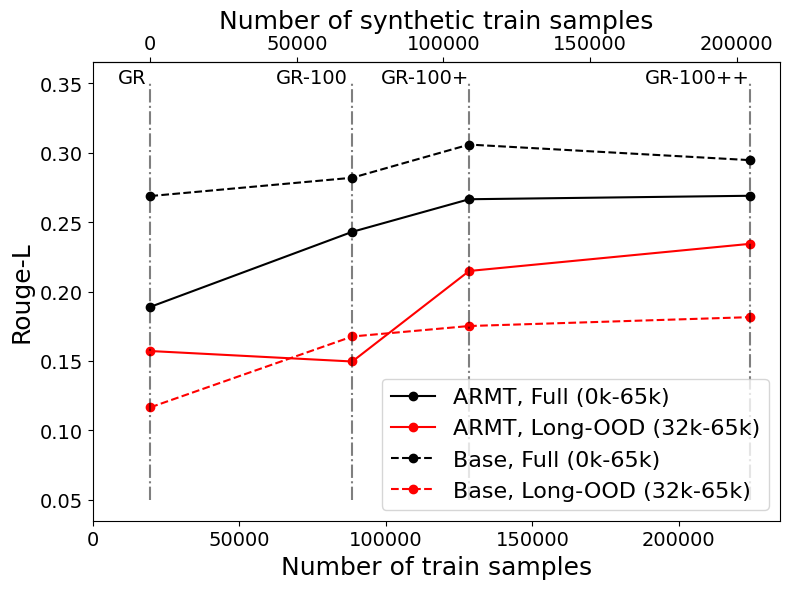

In [894]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8,6))
armt_idx = 4
# plot ARMT results
test_buckets = ["Full (0k-65k)", "In-Domain (0k-8k)", "OOD (8k-65k)"]#, "Long-OOD (32k-65k)"]
colors = ["k", "b", "r", "g"]
test_buckets = ["Full (0k-65k)", "Long-OOD (32k-65k)"]
colors = ["k", "r"]
for bucket, color in zip(test_buckets, colors):
    ax.plot(train_sizes, list(buf_res.loc[bucket])[armt_idx:], marker="o", label = f"ARMT, {bucket}", color=color)
    dnames = ["GR", "GR-100", "GR-100+", "GR-100++"]
    #idx = 0
    #for x, y, text in zip(train_sizes, list(buf_res.loc[bucket])[armt_idx:], dnames):
    #    if idx == 3:
    #        ax.text(x-25000, y-0.004, text)
    #    else:
    #        ax.text(x+2000, y-0.003, text)
    #    idx += 1


test_buckets = ["Full (0k-65k)", "In-Domain (0k-8k)", "OOD (8k-65k)"]#, "Long-OOD (32k-65k)"]
colors = ["k", "b", "r", "g"]
test_buckets = ["Full (0k-65k)", "Long-OOD (32k-65k)"]
colors = ["k", "r"]
for bucket, color in zip(test_buckets, colors):
    ax.plot(train_sizes, list(buf_res.loc[bucket])[:armt_idx], marker="o", label = f"Base, {bucket}", color=color, linestyle="--")
    dnames = ["GR", "GR-100", "GR-100+", "GR-100++"]

idx = 0
shift = [11000, 26000, 30000, 36000]
for x, y, text in zip(train_sizes, [0.36] * len(train_sizes), dnames):
    ax.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.vlines(train_sizes, ymin=0.05, ymax=0.35, color="k", linestyle="-.", alpha=0.5)
ax.set_xticks([0, 50000, 100000, 150000, 200000])
ax.set_xlabel("Number of train samples", fontsize=18)
ax.set_ylabel("Rouge-L", fontsize=18)
train2synth = lambda x: x - train_sizes[0]
synth2train = lambda x: x + train_sizes[0]
secax = ax.secondary_xaxis('top', functions=(train2synth, synth2train))
secax.set_xlabel("Number of synthetic train samples", fontsize=18)
#ax.set_title("Rouge-L for various GovReport versions")
ax.legend(fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=14)
secax.tick_params(axis='both', which='major', labelsize=14)
fig.tight_layout()
#fig.savefig("../../paper_results/synth_scaing_gr.pdf")#, layout='tight')

In [246]:
buf_res.loc["Full (0k-65k)"]

Model
Gemma-3-1B-IT, GR, 8k               0.268708
Gemma-3-1B-IT, GR-100, 8k           0.281882
Gemma-3-1B-IT, GR-100+, 8k          0.305758
Gemma-3-1B-IT, GR-100++, 8k         0.294559
ARMT-Gemma-3-1B-IT, GR, 8k          0.188935
ARMT-Gemma-3-1B-IT, GR-100, 8k      0.242962
ARMT-Gemma-3-1B-IT, GR-100+, 8k     0.266411
ARMT-Gemma-3-1B-IT, GR-100++, 8k    0.268913
Name: Full (0k-65k), dtype: float64

In [896]:
(train_sizes[2] - train_sizes[0]) / train_sizes[0]

5.525353114520882

In [412]:
d1 = datasets.load_from_disk("../../data/gov_report_100_gen_plus/gov_report_0k_8k/")

In [413]:
np.random.seed(43)
sub_ids = np.random.choice(np.arange(len(d1["train"])), len(d1["train"])//5, replace=False)

In [414]:
d1["train"] = d1["train"].select(sub_ids)

In [415]:
d1.save_to_disk("../../data/gov_report_100_gen_plus_subset_20_perc/gov_report_0k_8k/")

Saving the dataset (1/1 shards): 100%|██████████| 2543/2543 [00:00<00:00, 43546.18 examples/s]


### Best GR-100+, main results, for plot

In [37]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54] + [60,59,62] + [63,64, 68, 75,76,77, 132,133, 135, 200, 201,202,203]].round(3)

In [38]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [39]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [40]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained, 20%",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "Mamba-train-64",
    "Mamba-train-256",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain), top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain), top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), top-5 trained",
]

buf_res["Model"] = new_names

In [41]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
#buf_res = buf_res.loc[[13, 10,11,12] + [54] + [60,59,62, 63,64, 68]]
buf_res = buf_res.loc[[13, 10,11,12] + [54] + [62,  77, 132,133, 135, 200, 201,202, 203]]
#buf_res = buf_res.loc[[13, 12] + [54] + [62, 77]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [42]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",Mamba-train-64,Mamba-train-256,"ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain), top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain), top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), top-5 trained"
0k_1k,0.380,0.357,0.357,0.358,0.358,0.347,0.363,0.370,0.382,0.320,0.323,0.377,0.376,0.384
1k_2k,0.385,0.296,0.294,0.303,0.299,0.291,0.317,0.316,0.295,0.329,0.308,0.290,0.286,0.291
2k_4k,0.352,0.264,0.275,0.279,0.285,0.265,0.304,0.293,0.302,0.304,0.298,0.242,0.282,0.274
4k_6k,0.344,0.240,0.286,0.303,0.278,0.262,0.287,0.303,0.315,0.281,0.276,0.228,0.273,0.278
6k_8k,0.296,0.219,0.238,0.254,0.244,0.241,0.250,0.260,0.261,0.278,0.275,0.223,0.239,0.254
8k_10k,0.306,0.205,0.233,0.235,0.233,0.232,0.231,0.245,0.238,0.266,0.260,0.204,0.221,0.238
10k_12k,0.269,0.213,0.221,0.241,0.241,0.232,0.231,0.260,0.260,0.235,0.241,0.191,0.232,0.226
12k_14k,0.280,0.193,0.225,0.237,0.230,0.222,0.221,0.252,0.251,0.253,0.242,0.179,0.216,0.218
14k_16k,0.231,0.180,0.217,0.240,0.237,0.233,0.243,0.262,0.244,0.248,0.240,0.190,0.238,0.223
16k_24k,0.269,0.115,0.200,0.252,0.247,0.242,0.259,0.260,0.273,0.260,0.259,0.187,0.231,0.231


In [43]:
import matplotlib.pyplot as plt
import matplotlib as mpl


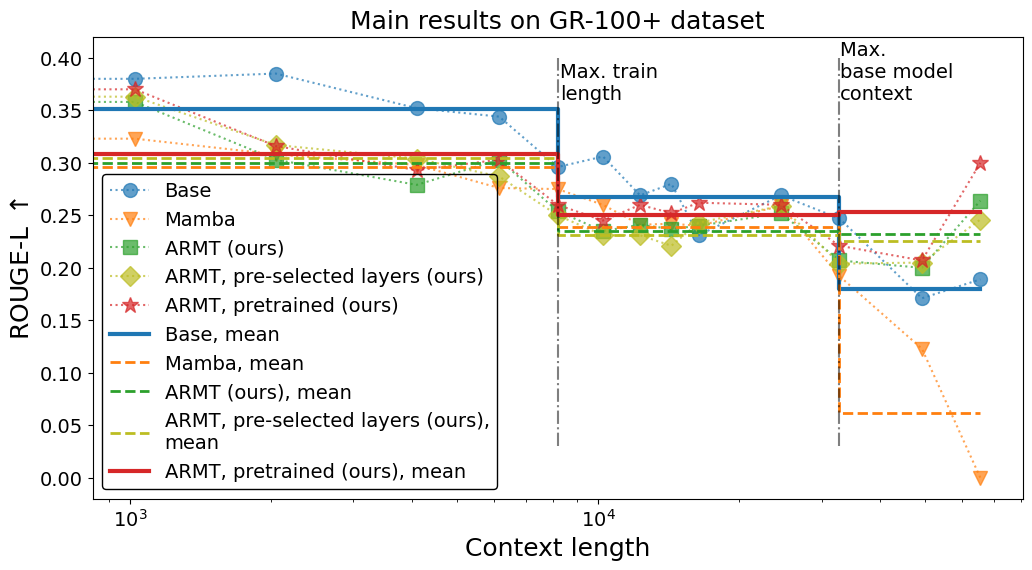

In [55]:

model_keys = [
    "Gemma-3-1B-IT, GR-100+, 8k",
    #"Mamba-train-64",
    "Mamba-train-256",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
]
model_names = [
    "Base",
    #"Mamba",
    "Mamba",
    "ARMT (ours)",
    #"ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    "ARMT, pre-selected layers (ours)",
    "ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(12,6))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 4]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    if "pre-selected layers" in name:
        plt.plot(new_x, new_y, label=name+",\nmean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
    else:
        plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.37] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("ROUGE-L $\\uparrow$", fontsize=global_fs)
plt.title("Main results on GR-100+ dataset", fontsize=global_fs)
plt.legend(fontsize=14)
legend = plt.legend(loc="lower left", fontsize=14, edgecolor="black")
legend.get_frame().set_alpha(None)
legend.get_frame().set_facecolor((0, 0, 1, 0.001))
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_gr100_plus_gemma_new_mamba_poster.pdf", transparent=True)

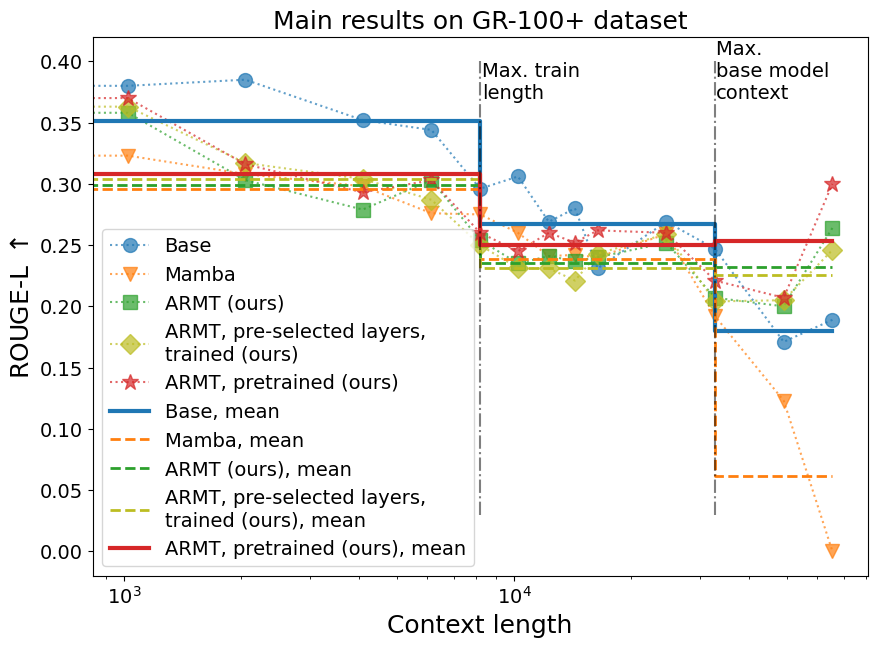

In [131]:

model_keys = [
    "Gemma-3-1B-IT, GR-100+, 8k",
    #"Mamba-train-64",
    "Mamba-train-256",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
]
model_names = [
    "Base",
    #"Mamba",
    "Mamba",
    "ARMT (ours)",
    #"ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    "ARMT, pre-selected layers, \ntrained (ours)",
    "ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 4]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.38] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("ROUGE-L $\\uparrow$", fontsize=global_fs)
plt.title("Main results on GR-100+ dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_gr100_plus_gemma_new_mamba.pdf")

In [818]:
cmap

((0.12156862745098039, 0.4666666666666667, 0.7058823529411765),
 (1.0, 0.4980392156862745, 0.054901960784313725),
 (0.17254901960784313, 0.6274509803921569, 0.17254901960784313),
 (0.8392156862745098, 0.15294117647058825, 0.1568627450980392),
 (0.5803921568627451, 0.403921568627451, 0.7411764705882353),
 (0.5490196078431373, 0.33725490196078434, 0.29411764705882354),
 (0.8901960784313725, 0.4666666666666667, 0.7607843137254902),
 (0.4980392156862745, 0.4980392156862745, 0.4980392156862745),
 (0.7372549019607844, 0.7411764705882353, 0.13333333333333333),
 (0.09019607843137255, 0.7450980392156863, 0.8117647058823529))

### Best GR-100+, SmolLM 360M, for plot

In [905]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 69,70,71,72,73,74, 81,82, 83, 88, 91]].round(3)

In [906]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [907]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [908]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 2k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-1850",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k-prelim",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k-prelim",

    "ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained",
    "SmolLM2-360M-IT, base prompt",
]
buf_res["Model"] = new_names

In [909]:
#buf_res = buf_res.loc[[69, 70,73,74, 81, 82 ]]
#buf_res = buf_res.loc[[91, 69, 70,73,83, 81, 82 ,88]]
buf_res = buf_res.loc[[69, 70,73,83, 81,82,88]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [910]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 2k","ARMT-SmolLM2-360M-IT, GR-100+, 4k","ARMT-SmolLM2-360M-IT, GR-100+, 8k","ARMT-SmolLM2-360M-IT, GR-100+, 2k, top-6-trained","ARMT-SmolLM2-360M-IT, GR-100+, 4k, top-6-trained","ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained"
0k_1k,0.349,0.335,0.332,0.337,0.345,0.346,0.329
1k_2k,0.358,0.289,0.297,0.302,0.261,0.257,0.252
2k_4k,0.330,0.238,0.257,0.261,0.230,0.242,0.248
4k_6k,0.314,0.220,0.245,0.253,0.204,0.226,0.236
6k_8k,0.286,0.212,0.215,0.225,0.180,0.219,0.220
8k_10k,0.233,0.177,0.202,0.221,0.157,0.186,0.199
10k_12k,0.021,0.156,0.199,0.211,0.159,0.202,0.199
12k_14k,0.035,0.137,0.195,0.215,0.134,0.186,0.199
14k_16k,0.049,0.074,0.190,0.210,0.157,0.202,0.213
16k_24k,0.037,0.046,0.140,0.219,0.156,0.203,0.208


In [911]:
import matplotlib.pyplot as plt
import matplotlib as mpl


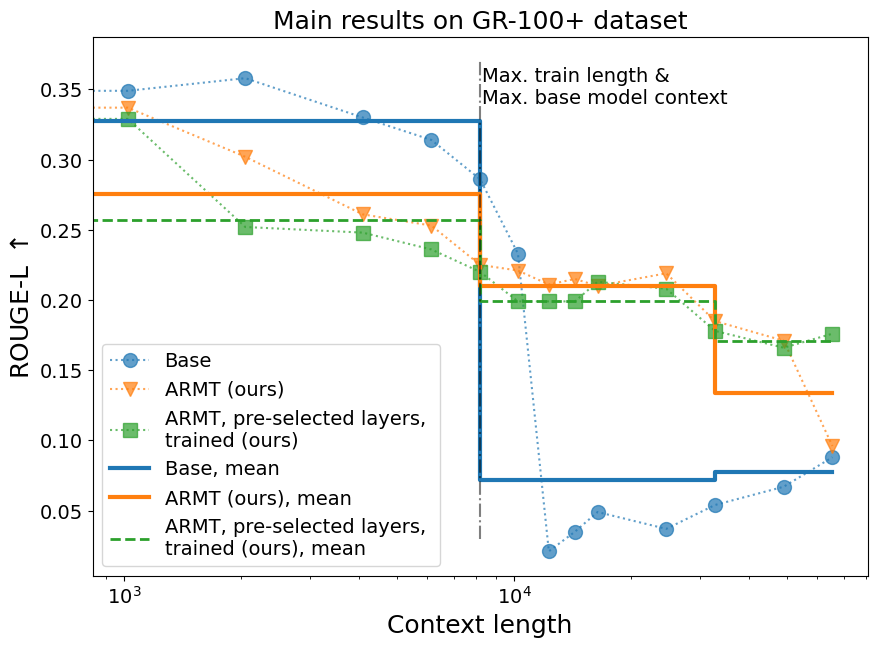

In [912]:

model_keys = [
    "SmolLM2-360M-IT, GR-100+, 8k",
    #"Mamba-1.3B gen64, MT, 8k",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    "ARMT-SmolLM2-360M-IT, GR-100+, 8k, top-6-trained",
]
model_names = [
    "Base",
    #"Mamba",
    "ARMT (ours)",
    #"ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    "ARMT, pre-selected layers, \ntrained (ours)",
]
fig = plt.figure(figsize=(10,7))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,2, 8, 3]
main_ids = [0, 1]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024

markers = ["o", "v", "s", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([8*1024], ymin=0.03, ymax=0.37, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024]#, 32*1024]
dnames = ["Max. train length & \nMax. base model context"]
idx = 0
for x, y, text in zip(train_sizes, [0.35] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("ROUGE-L $\\uparrow$", fontsize=global_fs)
plt.title("Main results on GR-100+ dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/main_res_gr100_plus_smollm.pdf")

### Best GR-100+, main ARMT results

In [878]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54] + [60,59,62] + [63,64, 68, 75,76,77, 132,133, 135]].round(3)

In [879]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [880]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [881]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained, 20%",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "Mamba-train-64",
]

buf_res["Model"] = new_names

In [882]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
#buf_res = buf_res.loc[[13, 10,11,12] + [54] + [60,59,62, 63,64, 68]]
buf_res = buf_res.loc[[19, 13, 12] + [ 77, 132]]
#buf_res = buf_res.loc[[13, 12] + [54] + [62, 77]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [883]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)"
0k_1k,0.188,0.380,0.358,0.363,0.370
1k_2k,0.161,0.385,0.303,0.317,0.316
2k_4k,0.140,0.352,0.279,0.304,0.293
4k_6k,0.114,0.344,0.303,0.287,0.303
6k_8k,0.113,0.296,0.254,0.250,0.260
8k_10k,0.106,0.306,0.235,0.231,0.245
10k_12k,0.101,0.269,0.241,0.231,0.260
12k_14k,0.091,0.280,0.237,0.221,0.252
14k_16k,0.088,0.231,0.240,0.243,0.262
16k_24k,0.083,0.269,0.252,0.259,0.260


In [884]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained & ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain) \\
\midrule
0k-1k & {\cellcolor[HTML]{FFB600}} \color[HTML]{000000} 0.188 & {\cellcolor[HTML]{088400}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{2C9600}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.363 & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.370 \\
1k-2k & {\cellcolor[HTML]{FF8A00}} \color[HTML]{F1F1F1} 0.161 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{88C400}} \color[HTML]{000000} 0.303 & {\cellcolor[HTML]{70B800}} \color[HTML]{F1F1F1} 0.317 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.316 \\
2k-4k & {\cellcolor[HTML]{FF6600}} \color[HTML]{F1F1F1} 0.140 & {\cellcolor[HTML]{369B00}} \color[HTML]{F1F1F1} 0.352 & {\cellcolor[HTML]{B0D800}} \color[HTML]{000000} 0.279 & {\

### Best GR-100+ from pretrain, assoc. ablation

In [941]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(141, 141+26)) + [51,52,53,54, 132]].round(3)

In [942]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [943]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [944]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
]

buf_res["Model"] = new_names

In [945]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
buf_res = buf_res.loc[[13, 132]+ list(range(141, 141+26))]
#buf_res = buf_res.loc[[13, 12]+ [21,22,23,24]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [946]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",W/o layer 0,W/o layer 1,W/o layer 2,W/o layer 3,W/o layer 4,W/o layer 5,W/o layer 6,W/o layer 7,W/o layer 8,W/o layer 9,W/o layer 10,W/o layer 11,W/o layer 12,W/o layer 13,W/o layer 14,W/o layer 15,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25
0k_1k,0.380,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370,0.370
1k_2k,0.385,0.316,0.316,0.307,0.309,0.314,0.309,0.314,0.316,0.313,0.307,0.316,0.316,0.250,0.306,0.316,0.316,0.316,0.316,0.313,0.312,0.313,0.320,0.305,0.316,0.311,0.315,0.304
2k_4k,0.352,0.293,0.280,0.302,0.295,0.295,0.287,0.291,0.293,0.295,0.281,0.286,0.299,0.226,0.298,0.293,0.293,0.293,0.303,0.289,0.298,0.293,0.294,0.288,0.293,0.285,0.284,0.287
4k_6k,0.344,0.303,0.279,0.306,0.304,0.299,0.308,0.304,0.303,0.308,0.308,0.303,0.295,0.208,0.290,0.303,0.303,0.303,0.303,0.302,0.287,0.302,0.302,0.296,0.303,0.302,0.307,0.304
6k_8k,0.296,0.260,0.244,0.262,0.260,0.259,0.263,0.262,0.260,0.265,0.252,0.257,0.258,0.198,0.247,0.260,0.260,0.260,0.256,0.260,0.258,0.260,0.242,0.256,0.260,0.255,0.261,0.252
8k_10k,0.306,0.245,0.238,0.243,0.244,0.249,0.241,0.244,0.245,0.246,0.245,0.244,0.247,0.181,0.253,0.245,0.245,0.245,0.244,0.248,0.244,0.243,0.242,0.247,0.245,0.245,0.238,0.243
10k_12k,0.269,0.260,0.234,0.265,0.259,0.263,0.259,0.259,0.260,0.264,0.250,0.262,0.261,0.194,0.249,0.260,0.260,0.260,0.262,0.253,0.235,0.260,0.246,0.249,0.260,0.253,0.262,0.256
12k_14k,0.280,0.252,0.226,0.243,0.251,0.248,0.242,0.250,0.252,0.249,0.243,0.250,0.246,0.179,0.242,0.252,0.252,0.252,0.248,0.249,0.239,0.252,0.247,0.239,0.252,0.240,0.238,0.243
14k_16k,0.231,0.262,0.242,0.262,0.256,0.261,0.260,0.260,0.262,0.260,0.256,0.260,0.254,0.182,0.248,0.262,0.262,0.262,0.254,0.247,0.238,0.261,0.248,0.255,0.262,0.257,0.250,0.256
16k_24k,0.269,0.260,0.236,0.273,0.267,0.260,0.265,0.270,0.260,0.272,0.269,0.266,0.267,0.193,0.249,0.260,0.260,0.260,0.275,0.269,0.225,0.260,0.257,0.263,0.260,0.261,0.261,0.257


### Best GR-100+ from pretrain, Gemma, top-5 pre-selected

In [190]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 16,17,18, 93,95, 132,133, 201,202,203, 204]].round(3)

In [191]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [192]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [193]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain), top-5-trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain), top-5-trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), top-5-trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), top-5-trained, w/o CL",
]
buf_res["Model"] = new_names

In [194]:
#buf_res = buf_res.loc[[13,10,11,12,16,17,18, 93,95]]
buf_res = buf_res.loc[[13,10,11,12, 93,95, 132, 133, 201,202,203, 204]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [195]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)","ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain), top-5-trained","ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain), top-5-trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), top-5-trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), top-5-trained, w/o CL"
0k_1k,0.380,0.357,0.357,0.358,0.371,0.384,0.370,0.382,0.377,0.376,0.384,0.359
1k_2k,0.385,0.296,0.294,0.303,0.310,0.320,0.316,0.295,0.290,0.286,0.291,0.302
2k_4k,0.352,0.264,0.275,0.279,0.268,0.301,0.293,0.302,0.242,0.282,0.274,0.266
4k_6k,0.344,0.240,0.286,0.303,0.254,0.293,0.303,0.315,0.228,0.273,0.278,0.273
6k_8k,0.296,0.219,0.238,0.254,0.222,0.256,0.260,0.261,0.223,0.239,0.254,0.246
8k_10k,0.306,0.205,0.233,0.235,0.135,0.228,0.245,0.238,0.204,0.221,0.238,0.228
10k_12k,0.269,0.213,0.221,0.241,0.052,0.231,0.260,0.260,0.191,0.232,0.226,0.236
12k_14k,0.280,0.193,0.225,0.237,0.033,0.237,0.252,0.251,0.179,0.216,0.218,0.222
14k_16k,0.231,0.180,0.217,0.240,0.026,0.224,0.262,0.244,0.190,0.238,0.223,0.240
16k_24k,0.269,0.115,0.200,0.252,0.010,0.246,0.260,0.273,0.187,0.231,0.231,0.229


In [768]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lcccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain) & ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain) & ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain) & ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL) \\
\midrule
0k-1k & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{128900}} \color[HTML]{F1F1F1} 0.371 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.384 & {\cellcolor[HTML]{128900}} \color[HTML]{F1F1F1} 0.370 & {\cellcolor[HTML]{028100}} \color[HTML]{F1F1F1} 0.382 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.

### Some loss evals

In [155]:
p1 = "/home/jovyan/gkuzmin/rmt_it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/from_new_pretrain_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-1350/trainer_state.json"
p2 = "/home/jovyan/gkuzmin/rmt_it/runs/finetune/armt_sw/gov_report_100_gen_plus/gov_report_0k_2k/google/gemma-3-1b-it/steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_2x1024_2016_64_1e-04_5000/checkpoint-5000/trainer_state.json"

In [156]:
import json
with open(p1, "r") as f:
    d_loss = json.load(f)
with open(p2, "r") as f:
    d_loss_base = json.load(f)

In [159]:
hist = d_loss["log_history"]
x, y = [], []
for el in hist:
    if "eval_loss" in el.keys():
        x += [el["epoch"]]
        y += [el["eval_loss"]]
hist_base = d_loss_base["log_history"]
x_base, y_base = [], []
for el in hist_base:
    if "eval_loss" in el.keys():
        x_base += [el["epoch"]]
        y_base += [el["eval_loss"]]

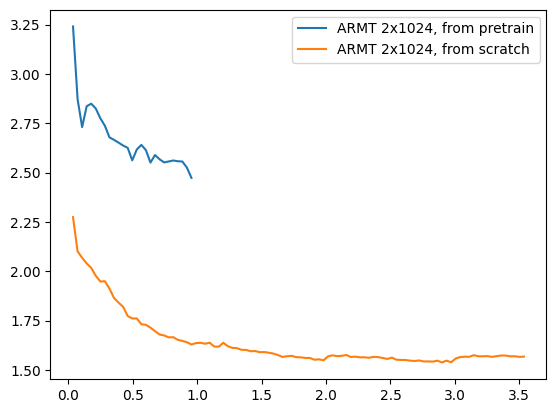

In [160]:
import matplotlib.pyplot as plt
plt.plot(x, y, label='ARMT 2x1024, from pretrain')
plt.plot(x_base, y_base, label='ARMT 2x1024, from scratch')
plt.legend()

In [230]:
from transformers import AutoModelForCausalLM

In [163]:
mod = AutoModelForCausalLM.from_pretrained("google/gemma-3-1b-it")

In [166]:
trainable_params = sum(p.numel() for p in mod.parameters())# if p.requires_grad)

In [167]:
trainable_params

999885952

In [172]:
1152 * (1152+128+1) * 26  +trainable_params + 1152*32

1038291328

In [170]:
mod = AutoModelForCausalLM.from_pretrained("../../data/pretrained_models/InnerLoopARMTForCausalLM_run_35", trust_remote_code=True)

*** Can't import RWKV model ***
*** Can't import liger_kernel ***
*** Can't import liger_kernel ***
*** Can't import liger_kernel ***


ImportError: FlashAttention2 has been toggled on, but it cannot be used due to the following error: the package flash_attn seems to be not installed. Please refer to the documentation of https://huggingface.co/docs/transformers/perf_infer_gpu_one#flashattention-2 to install Flash Attention 2.

In [171]:
del mod

In [197]:
a = "model.model.layers.0.layer.self_attn.o_proj.weight"

In [198]:
a[12:]#.strip("model",)

'layers.0.layer.self_attn.o_proj.weight'

In [231]:
mod = AutoModelForCausalLM.from_pretrained("../../data/pretrained_models/ARMT-SmolLM2-360m-8x1024/", trust_remote_code=True, attn)

*** Can't import RWKV model ***
*** Can't import liger_kernel ***
*** Can't import liger_kernel ***
*** Can't import liger_kernel ***


ImportError: FlashAttention2 has been toggled on, but it cannot be used due to the following error: the package flash_attn seems to be not installed. Please refer to the documentation of https://huggingface.co/docs/transformers/perf_infer_gpu_one#flashattention-2 to install Flash Attention 2.

## After ARR deadline

### Best GR-100+ with pretrain VS mem 32, Gemma

In [230]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 16,17,18, 93,95, 132,133, 167,168,169]].round(3)

In [231]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [232]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [233]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 8k",
]
buf_res["Model"] = new_names

In [234]:
#buf_res = buf_res.loc[[13,10,11,12,16,17,18, 93,95]]
#buf_res = buf_res.loc[[13,10,11,12, 93,95, 132, 167,168,169]]
buf_res = buf_res.loc[[13,10,11,12, 167,168,169]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [235]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 2k","ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 4k","ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 8k"
0k_1k,0.380,0.357,0.357,0.358,0.339,0.349,0.346
1k_2k,0.385,0.296,0.294,0.303,0.296,0.299,0.305
2k_4k,0.352,0.264,0.275,0.279,0.249,0.290,0.277
4k_6k,0.344,0.240,0.286,0.303,0.235,0.263,0.290
6k_8k,0.296,0.219,0.238,0.254,0.227,0.239,0.248
8k_10k,0.306,0.205,0.233,0.235,0.190,0.238,0.244
10k_12k,0.269,0.213,0.221,0.241,0.159,0.227,0.225
12k_14k,0.280,0.193,0.225,0.237,0.105,0.201,0.232
14k_16k,0.231,0.180,0.217,0.240,0.043,0.157,0.240
16k_24k,0.269,0.115,0.200,0.252,0.016,0.046,0.241


In [236]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 2k & ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 4k & ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{3C9E00}} \color[HTML]{F1F1F1} 0.339 & {\cellcolor[HTML]{2E9700}} \color[HTML]{F1F1F1} 0.349 & {\cellcolor[HTML]{329900}} \color[HTML]{F1F1F1} 0.346 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.294 & {\cellcolor[HTML]{6CB600}} \color[HTML]{F1F1F1} 0.303 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {

### Best GR-100+, assoc. ablation, mem 32

In [47]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24] + [51,52,53,54] + [167,168,169]+ list(range(170, 170+26))].round(3)

In [48]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [49]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [50]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
#new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 8k",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
buf_res["Model"] = new_names

In [51]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25+13, 25+26))]
buf_res = buf_res.loc[[13, 169]+ list(range(170, 170+26))]
#buf_res = buf_res.loc[[13, 12]+ [21,22,23,24]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [52]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 8k",W/o layer 0,W/o layer 1,W/o layer 2,W/o layer 3,W/o layer 4,W/o layer 5,W/o layer 6,W/o layer 7,W/o layer 8,W/o layer 9,W/o layer 10,W/o layer 11,W/o layer 12,W/o layer 13,W/o layer 14,W/o layer 15,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25
0k_1k,0.380,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346,0.346
1k_2k,0.385,0.305,0.300,0.298,0.303,0.300,0.303,0.307,0.305,0.303,0.298,0.303,0.295,0.305,0.303,0.297,0.223,0.306,0.304,0.305,0.292,0.301,0.305,0.298,0.305,0.301,0.308,0.232
2k_4k,0.352,0.277,0.280,0.276,0.277,0.281,0.277,0.278,0.278,0.271,0.277,0.270,0.275,0.277,0.276,0.269,0.209,0.278,0.275,0.277,0.269,0.273,0.277,0.273,0.277,0.275,0.279,0.205
4k_6k,0.344,0.290,0.292,0.288,0.291,0.291,0.291,0.288,0.291,0.290,0.291,0.279,0.286,0.290,0.286,0.277,0.179,0.290,0.290,0.290,0.253,0.291,0.290,0.288,0.290,0.293,0.290,0.190
6k_8k,0.296,0.248,0.244,0.243,0.249,0.245,0.245,0.244,0.247,0.245,0.239,0.246,0.250,0.248,0.255,0.245,0.182,0.249,0.247,0.248,0.251,0.247,0.248,0.245,0.248,0.246,0.248,0.205
8k_10k,0.306,0.244,0.240,0.242,0.243,0.242,0.241,0.245,0.244,0.237,0.239,0.237,0.243,0.244,0.245,0.239,0.172,0.244,0.243,0.244,0.242,0.243,0.244,0.242,0.244,0.240,0.241,0.181
10k_12k,0.269,0.225,0.228,0.227,0.226,0.227,0.228,0.228,0.228,0.230,0.230,0.224,0.232,0.225,0.228,0.231,0.163,0.226,0.226,0.225,0.227,0.226,0.225,0.225,0.225,0.224,0.227,0.185
12k_14k,0.280,0.232,0.231,0.228,0.233,0.234,0.231,0.227,0.231,0.232,0.228,0.231,0.226,0.232,0.235,0.224,0.164,0.232,0.232,0.232,0.229,0.233,0.232,0.235,0.232,0.235,0.232,0.175
14k_16k,0.231,0.240,0.237,0.237,0.242,0.239,0.239,0.243,0.244,0.231,0.242,0.222,0.244,0.240,0.236,0.229,0.163,0.240,0.238,0.240,0.234,0.242,0.240,0.239,0.240,0.239,0.239,0.184
16k_24k,0.269,0.241,0.244,0.245,0.246,0.244,0.242,0.241,0.240,0.241,0.248,0.241,0.245,0.241,0.244,0.250,0.176,0.242,0.241,0.241,0.242,0.242,0.241,0.239,0.241,0.242,0.241,0.182


### Eval losses for layers ablation

In [64]:
import json

In [72]:
pt_armt_gemma_pathes = [
    "../../runs/finetune/armt_sw/fineweb_train_subset_karp/google/gemma-3-1b-it/from_new_pretrain_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10"
]
pt_armt_gemma_pathes += [
    f"../../runs/finetune/armt_sw/fineweb_train_subset_karp/google/gemma-3-1b-it/layers_ablation/removed_{idx}_from_new_pretrain_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10" for idx in range(26)
]

pt_armt_gemma_names = ["ARMT-Gemma3-1b-IT-pt"]
pt_armt_gemma_names += [f"W/o layer {idx}" for idx in range(26)]

In [73]:
eval_losses_abl_gemma = {}
for path, name in zip(pt_armt_gemma_pathes, pt_armt_gemma_names):
    with open(path + "/val_scores.json", "r") as f:
        buf_data = json.load(f)
    eval_losses_abl_gemma[name] = [buf_data["eval_loss"]]

In [74]:
gemma_abl_df = pd.DataFrame.from_dict(eval_losses_abl_gemma)

In [75]:
##new_names = [f"W/o layer {idx}" for idx in range(26)]
#new_names += [f"W/o layer {idx}" for idx in range(26)]
#buf_res["Model"] = new_names

In [76]:
gemma_abl_df

,ARMT-Gemma3-1b-IT-pt,W/o layer 0,W/o layer 1,W/o layer 2,W/o layer 3,W/o layer 4,W/o layer 5,W/o layer 6,W/o layer 7,W/o layer 8,...,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25
0,2.25812,2.447975,2.870912,2.513906,2.530164,6.825995,3.09158,3.04559,2.785349,2.607792,...,2.462763,2.44471,2.402534,2.374442,2.385026,2.36922,2.362076,2.357257,2.344375,2.321458


In [79]:
s = gemma_abl_df.style
from pandas import option_context
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('gyr', ["green", "yellow", "red"], N=256)

fres = s.format(precision=2).background_gradient(axis=None, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,ARMT-Gemma3-1b-IT-pt,W/o layer 0,W/o layer 1,W/o layer 2,W/o layer 3,W/o layer 4,W/o layer 5,W/o layer 6,W/o layer 7,W/o layer 8,W/o layer 9,W/o layer 10,W/o layer 11,W/o layer 12,W/o layer 13,W/o layer 14,W/o layer 15,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25
0,2.26,2.45,2.87,2.51,2.53,6.83,3.09,3.05,2.79,2.61,2.62,2.54,2.49,2.54,2.51,2.47,2.48,2.46,2.44,2.40,2.37,2.39,2.37,2.36,2.36,2.34,2.32


In [84]:
#gkuzmin/rmt_it/runs/finetune/armt_sw/fineweb_train_subset_karp/HuggingFaceTB/SmolLM2-360M-Instruct/layers_ablation/removed_0_from_new_pretrain_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10

pt_armt_gemma_pathes = [
    "../../runs/finetune/armt_sw/fineweb_train_subset_karp/HuggingFaceTB/SmolLM2-360M-Instruct/layers_ablation/removed_-1_from_new_pretrain_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10"
]
pt_armt_gemma_pathes += [
    f"../../runs/finetune/armt_sw/fineweb_train_subset_karp/HuggingFaceTB/SmolLM2-360M-Instruct/layers_ablation/removed_{idx}_from_new_pretrain_steps_2k_bl_pars_mask_fix_assist_mask_es15_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_10" for idx in range(32)
]

pt_armt_gemma_names = ["ARMT-Smollm2-360m-IT-pt"]
pt_armt_gemma_names += [f"W/o layer {idx}" for idx in range(32)]

In [85]:
eval_losses_abl_gemma = {}
for path, name in zip(pt_armt_gemma_pathes, pt_armt_gemma_names):
    with open(path + "/val_scores.json", "r") as f:
        buf_data = json.load(f)
    eval_losses_abl_gemma[name] = [buf_data["eval_loss"]]

In [86]:
gemma_abl_df = pd.DataFrame.from_dict(eval_losses_abl_gemma)

In [87]:
##new_names = [f"W/o layer {idx}" for idx in range(26)]
#new_names += [f"W/o layer {idx}" for idx in range(26)]
#buf_res["Model"] = new_names

In [88]:
gemma_abl_df

,ARMT-Smollm2-360m-IT-pt,W/o layer 0,W/o layer 1,W/o layer 2,W/o layer 3,W/o layer 4,W/o layer 5,W/o layer 6,W/o layer 7,W/o layer 8,...,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25,W/o layer 26,W/o layer 27,W/o layer 28,W/o layer 29,W/o layer 30,W/o layer 31
0,6.147115,6.10453,5.953142,5.912075,5.914352,5.923404,5.921908,5.921792,5.911556,5.921277,...,6.229671,6.424195,6.470143,6.451925,6.556206,6.697688,6.776507,6.794,6.728387,6.61065


In [89]:
s = gemma_abl_df.style
from pandas import option_context
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('gyr', ["green", "yellow", "red"], N=256)

fres = s.format(precision=2).background_gradient(axis=None, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,ARMT-Smollm2-360m-IT-pt,W/o layer 0,W/o layer 1,W/o layer 2,W/o layer 3,W/o layer 4,W/o layer 5,W/o layer 6,W/o layer 7,W/o layer 8,W/o layer 9,W/o layer 10,W/o layer 11,W/o layer 12,W/o layer 13,W/o layer 14,W/o layer 15,W/o layer 16,W/o layer 17,W/o layer 18,W/o layer 19,W/o layer 20,W/o layer 21,W/o layer 22,W/o layer 23,W/o layer 24,W/o layer 25,W/o layer 26,W/o layer 27,W/o layer 28,W/o layer 29,W/o layer 30,W/o layer 31
0,6.15,6.10,5.95,5.91,5.91,5.92,5.92,5.92,5.91,5.92,5.90,5.90,5.90,5.89,5.92,6.02,6.03,6.04,6.07,6.08,6.08,6.17,6.19,6.23,6.42,6.47,6.45,6.56,6.70,6.78,6.79,6.73,6.61


### Build longbench scores after SFT

In [245]:
longbench_pathes = [
    "../../harness_results/longbench_e/HuggingFaceTB/SmolLM2-360M/no-template",
    "../../harness_results/longbench_e/HuggingFaceTB/SmolLM2-360M-Instruct/no-template",
    "../../harness_results/longbench_e/irodkin/ARMT-SmolLM2-360m-8x1024/no-template",
    "../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_10000/checkpoint-7000/no-template/",
    #"../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-03_10000/checkpoint-3500/no-template/",
    #"../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/packed_full_mask_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-03_1000/checkpoint-300/no-template/",
    "../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_20000/checkpoint-7800/no-template/",
    "../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_20000/checkpoint-7100/no-template/",

    #"../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/grad_ckpt_sub_30_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-03_3000/checkpoint-2100/no-template/",
    
]

names_lb = [
    "SmolLM2-360M",
    "SmolLM2-360M-Instruct",
    "ARMT-SmolLM-2-360M-PT",
    "ARMT-SmolLM-2-360M-PT+SFT-1e-5",
    #"ARMT-SmolLM-2-360M-PT+SFT-1e-3",
    #"ARMT-SmolLM-2-360M-PT+SFT-pack-full-mask-1e-3",
    "ARMT-SmolLM-2-360M-PT+SFT-1e-5, Smoltalk-full",
    "ARMT-SmolLM-2-360M-PT+SFT-1e-4, Smoltalk-full",
    #"ARMT-SmolLM-2-360M-SFT-1e-3, 30% data",
    
]

In [246]:
res_keys = ['longbench_code_e', 'longbench_fewshot_e', 'longbench_multi_e', 'longbench_single_e', 'longbench_e']

In [247]:
eval_losses_abl_gemma = {}
for path, name in zip(longbench_pathes, names_lb):
    with open(path + "/results_only.json", "r") as f:
        buf_data = json.load(f)
    #eval_losses_abl_gemma[name] = {key: f"{np.round(buf_data[key]['score,none']*100, 2)}±{np.round(buf_data[key]['score_stderr,none']*100, 2)}" for key in res_keys}
    eval_losses_abl_gemma[name] = {key: np.round(buf_data[key]['score,none']*100, 2) for key in res_keys}

In [248]:
longbench_df = pd.DataFrame.from_dict(eval_losses_abl_gemma)

In [249]:
longbench_df

,SmolLM2-360M,SmolLM2-360M-Instruct,ARMT-SmolLM-2-360M-PT,ARMT-SmolLM-2-360M-PT+SFT-1e-5,"ARMT-SmolLM-2-360M-PT+SFT-1e-5, Smoltalk-full","ARMT-SmolLM-2-360M-PT+SFT-1e-4, Smoltalk-full"
longbench_code_e,42.13,45.18,21.25,22.67,32.03,30.48
longbench_fewshot_e,51.00,25.89,28.37,28.01,24.19,29.40
longbench_multi_e,6.50,0.64,4.78,7.18,7.17,7.07
longbench_single_e,6.45,8.42,5.00,10.13,10.15,9.98
longbench_e,29.24,20.68,16.35,18.22,19.03,20.36


In [250]:
s = longbench_df.style
from pandas import option_context
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=2).background_gradient(axis=None, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,SmolLM2-360M,SmolLM2-360M-Instruct,ARMT-SmolLM-2-360M-PT,ARMT-SmolLM-2-360M-PT+SFT-1e-5,"ARMT-SmolLM-2-360M-PT+SFT-1e-5, Smoltalk-full","ARMT-SmolLM-2-360M-PT+SFT-1e-4, Smoltalk-full"
longbench_code_e,42.13,45.18,21.25,22.67,32.03,30.48
longbench_fewshot_e,51.00,25.89,28.37,28.01,24.19,29.40
longbench_multi_e,6.50,0.64,4.78,7.18,7.17,7.07
longbench_single_e,6.45,8.42,5.00,10.13,10.15,9.98
longbench_e,29.24,20.68,16.35,18.22,19.03,20.36


### Build longbench scores after SFT, with length split

In [251]:
import json
import pandas as pd

In [252]:
longbench_pathes = [
    "../../harness_results/longbench_e/HuggingFaceTB/SmolLM2-360M/no-template",
    "../../harness_results/longbench_e/HuggingFaceTB/SmolLM2-360M-Instruct/no-template",
    "../../harness_results/longbench_e/irodkin/ARMT-SmolLM2-360m-8x1024/no-template",
    "../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_10000/checkpoint-7000/no-template/",
    #"../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-03_10000/checkpoint-3500/no-template/",
    #"../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/packed_full_mask_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-03_1000/checkpoint-300/no-template/",
    "../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-05_20000/checkpoint-7800/no-template/",
    "../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/recalc_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-04_20000/checkpoint-7100/no-template/",

    #"../../../runs/inst_pretrain_armt_sw/sft_from_pretrain/smol_smoltalk/HuggingFaceTB/SmolLM2-360M-Instruct/grad_ckpt_sub_30_no_lora_paper_version_mask_fix_assist_mask_no_sw_all_lin_64_128_sink_SEGM_8x1024_7936_64_1e-03_3000/checkpoint-2100/no-template/",
    
]

names_lb = [
    "SmolLM2-360M",
    "SmolLM2-360M-Instruct",
    "ARMT-SmolLM-2-360M-PT",
    "ARMT-SmolLM-2-360M-PT+SFT-1e-5",
    #"ARMT-SmolLM-2-360M-PT+SFT-1e-3",
    #"ARMT-SmolLM-2-360M-PT+SFT-pack-full-mask-1e-3",
    "ARMT-SmolLM-2-360M-PT+SFT-1e-5, Smoltalk-full",
    "ARMT-SmolLM-2-360M-PT+SFT-1e-4, Smoltalk-full",
    #"ARMT-SmolLM-2-360M-SFT-1e-3, 30% data",
    
]

In [253]:
res_keys = ['longbench_code_e', 'longbench_fewshot_e', 'longbench_multi_e', 'longbench_single_e', 'longbench_e']

In [254]:
eval_losses_abl_gemma = {}
for path, name in zip(longbench_pathes, names_lb):
    with open(path + "/results_only.json", "r") as f:
        buf_data = json.load(f)
    #eval_losses_abl_gemma[name] = {key: f"{np.round(buf_data[key]['score,none']*100, 2)}±{np.round(buf_data[key]['score_stderr,none']*100, 2)}" for key in res_keys}
    eval_losses_abl_gemma[name] = {key: np.round(buf_data[key]['score,none']*100, 2) for key in res_keys}

In [255]:
longbench_df = pd.DataFrame.from_dict(eval_losses_abl_gemma)

In [256]:
longbench_df

,SmolLM2-360M,SmolLM2-360M-Instruct,ARMT-SmolLM-2-360M-PT,ARMT-SmolLM-2-360M-PT+SFT-1e-5,"ARMT-SmolLM-2-360M-PT+SFT-1e-5, Smoltalk-full","ARMT-SmolLM-2-360M-PT+SFT-1e-4, Smoltalk-full"
longbench_code_e,42.13,45.18,21.25,22.67,32.03,30.48
longbench_fewshot_e,51.00,25.89,28.37,28.01,24.19,29.40
longbench_multi_e,6.50,0.64,4.78,7.18,7.17,7.07
longbench_single_e,6.45,8.42,5.00,10.13,10.15,9.98
longbench_e,29.24,20.68,16.35,18.22,19.03,20.36


In [257]:
s = longbench_df.style
from pandas import option_context
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=2).background_gradient(axis=None, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

,SmolLM2-360M,SmolLM2-360M-Instruct,ARMT-SmolLM-2-360M-PT,ARMT-SmolLM-2-360M-PT+SFT-1e-5,"ARMT-SmolLM-2-360M-PT+SFT-1e-5, Smoltalk-full","ARMT-SmolLM-2-360M-PT+SFT-1e-4, Smoltalk-full"
longbench_code_e,42.13,45.18,21.25,22.67,32.03,30.48
longbench_fewshot_e,51.00,25.89,28.37,28.01,24.19,29.40
longbench_multi_e,6.50,0.64,4.78,7.18,7.17,7.07
longbench_single_e,6.45,8.42,5.00,10.13,10.15,9.98
longbench_e,29.24,20.68,16.35,18.22,19.03,20.36


In [258]:
def get_len_score(data, splits, metric_key):
    samples = []
    scores = []
    lens = []
    for split in splits:
        for idx in range(len(data["samples"][split])):
            samples.append(data["samples"][split][idx]["arguments"][0][0])
            scores.append(data["samples"][split][idx]["score"])
            lens.append(len(tok(samples[-1])["input_ids"]))#data["samples"][split][idx]["doc"]["length"])
    return samples, scores, lens

In [259]:
tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-360M")

In [260]:
res_keys = ['longbench_code_e', 'longbench_fewshot_e', 'longbench_multi_e', 'longbench_single_e', 'longbench_e']
res_sets = [
    ["longbench_repobench-p_e", "longbench_lcc_e"],
    ["longbench_trec_e", "longbench_triviaqa_e", "longbench_samsum_e"],
    ["longbench_hotpotqa_e", "longbench_2wikimqa_e"],
    ["longbench_qasper_e", "longbench_multifieldqa_en_e"],
    ["longbench_repobench-p_e", "longbench_lcc_e", "longbench_trec_e", "longbench_triviaqa_e", "longbench_samsum_e", "longbench_hotpotqa_e", "longbench_2wikimqa_e", "longbench_qasper_e", "longbench_multifieldqa_en_e"],
]
len_sets = [[0, 1e6], [0, 8192], [8192, 32*1024], [32*1024, 128*1024]]

In [261]:
def score_by_len(scores, lens, min_len, max_len):
    score_ids = [idx for idx, el in enumerate(lens) if el > min_len and el < max_len]
    return np.round(np.mean(np.array(scores)[score_ids]) * 100, 2)

In [262]:
def get_len_split_scores(buf_data, res_keys, res_sets, len_sets):
    data_score = {}
    for idx, res_set in enumerate(res_sets):
        data_score[res_keys[idx]] = {}
        samples, scores, lens = get_len_score(buf_data, res_set, None)
        for len_set in len_sets:
            data_score[res_keys[idx]][f"{len_set[0]}_{len_set[1]}"] = score_by_len(scores, lens, len_set[0], len_set[1])
    return data_score

In [263]:
def flatten_dict(d, parent_key='', sep='_'):
    items = []
    for k, v in d.items():
        new_key = f"{parent_key}{sep}{k}" if parent_key else k
        if isinstance(v, dict):
            items.extend(flatten_dict(v, new_key, sep=sep).items())
        else:
            items.append((new_key, v))
    return dict(items)

In [264]:
#data_score = get_len_split_scores(buf_data, res_keys, res_sets, len_sets)

In [265]:
#data_score

In [ ]:
eval_losses_abl_gemma = {}
for path, name in zip(longbench_pathes, names_lb):
    print(name)
    with open(path + "/results.json", "r") as f:
        buf_data = json.load(f)
    #eval_losses_abl_gemma[name] = {key: f"{np.round(buf_data[key]['score,none']*100, 2)}±{np.round(buf_data[key]['score_stderr,none']*100, 2)}" for key in res_keys}
    eval_losses_abl_gemma[name] = get_len_split_scores(buf_data, res_keys, res_sets, len_sets)

SmolLM2-360M


Token indices sequence length is longer than the specified maximum sequence length for this model (8595 > 8192). Running this sequence through the model will result in indexing errors
/home/jovyan/gkuzmin/llm_ue/conda_llm_ue_env/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jovyan/gkuzmin/llm_ue/conda_llm_ue_env/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


SmolLM2-360M-Instruct
ARMT-SmolLM-2-360M-PT
ARMT-SmolLM-2-360M-PT+SFT-1e-5
ARMT-SmolLM-2-360M-PT+SFT-1e-5, Smoltalk-full
ARMT-SmolLM-2-360M-PT+SFT-1e-4, Smoltalk-full


In [ ]:
eval_losses_abl_gemma_rebuilt = {}
for name in names_lb:
    eval_losses_abl_gemma_rebuilt[name] = {}
    for key in eval_losses_abl_gemma[name].keys():
        eval_losses_abl_gemma_rebuilt[name] = flatten_dict(eval_losses_abl_gemma[name], parent_key=key)

In [ ]:
eval_losses_abl_gemma_rebuilt_multi = []
for name in names_lb:
    df_new = pd.DataFrame(
        [
            (outer_k, inner_k, value)
            for outer_k, inner_dict in eval_losses_abl_gemma[name].items()
            for inner_k, value in inner_dict.items()
        ],
        columns=['Task', 'Range', name]
    ).set_index(['Task', 'Range'])
    eval_losses_abl_gemma_rebuilt_multi.append(df_new)

In [ ]:
multirow_res = pd.concat(eval_losses_abl_gemma_rebuilt_multi, axis=1)

In [ ]:
old_index = multirow_res.index
new_index = []
for idx in range(len(old_index)):
    new_index.append((old_index[idx][0],
                      old_index[idx][1].replace('0_1000000.0', "Full").replace("0_8192", "0-8k").replace('8192_32768', "8-32k").replace('32768_131072', "32-128k")))
new_index = pd.MultiIndex.from_tuples(new_index, names=['Task', 'Range'])

In [ ]:
multirow_res.index = new_index

In [ ]:
multirow_res_clear = multirow_res.dropna()

In [274]:
s = multirow_res_clear.style
from pandas import option_context
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)
for l0 in ["longbench_e_longbench_code_e_0_1000000.0", "longbench_e_longbench_fewshot_e_0_1000000.0", "longbench_e_longbench_multi_e_0_1000000.0", "longbench_e_longbench_single_e_0_1000000.0", "longbench_e_longbench_e_0_1000000.0"]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [("longbench_code_e", "32-128k"), ("longbench_fewshot_e", "32-128k"), ("longbench_multi_e", "8-32k"), ("longbench_single_e", "8-32k")]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
fres = s.format(precision=2).background_gradient(axis=1, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

In [59]:

split = "longbench_repobench-p_e"
samples, scores, lens = get_len_score(buf_data, split, None)

In [60]:

split = "longbench_lcc_e"
samples_1, scores_1, lens_1 = get_len_score(buf_data, split, None)

In [57]:
lens[:2]

[4771, 5326]

In [50]:
len(tok(samples[0])["input_ids"])

4771

In [47]:
len(samples[0].split())

3610

In [61]:
np.mean(scores), np.mean(scores_1)

(0.3885, 0.4541333333333334)

In [62]:
np.mean(scores + scores_1)

0.42131666666666673

In [42]:
buf_data["results"]#.keys()

{'longbench_lcc_e': {'name': 'longbench_lcc_e',
  'alias': 'longbench_lcc_e',
  'sample_len': 300,
  'score,none': 0.45413333333333317,
  'score_stderr,none': 0.018552848575457154,
  'code_sim_score,none': 0.45413333333333317,
  'code_sim_score_stderr,none': 0.018552848575457154},
 'longbench_repobench-p_e': {'name': 'longbench_repobench-p_e',
  'alias': 'longbench_repobench-p_e',
  'sample_len': 300,
  'score,none': 0.38849999999999973,
  'score_stderr,none': 0.01572351163968044,
  'code_sim_score,none': 0.38849999999999973,
  'code_sim_score_stderr,none': 0.01572351163968044},
 'longbench_trec_e': {'name': 'longbench_trec_e',
  'alias': 'longbench_trec_e',
  'sample_len': 300,
  'score,none': 0.5233333333333333,
  'score_stderr,none': 0.028884243402038653,
  'classification_score,none': 0.5233333333333333,
  'classification_score_stderr,none': 0.028884243402038653},
 'longbench_triviaqa_e': {'name': 'longbench_triviaqa_e',
  'alias': 'longbench_triviaqa_e',
  'sample_len': 300,
  'sc

In [33]:
buf_data["samples"]["longbench_qasper_e"][0]["arguments"][0][0]

'You are given a scientific article and a question. Answer the question as concisely as you can, using a single phrase or sentence if possible. If the question cannot be answered based on the information in the article, write "unanswerable". If the question is a yes/no question, answer "yes", "no", or "unanswerable". Do not provide any explanation.\n\nArticle: You are given a scientific article and a question. Answer the question as concisely as you can, using a single phrase or sentence if possible. If the question cannot be answered based on the information in the article, write "unanswerable". If the question is a yes/no question, answer "yes", "no", or "unanswerable". Do not provide any explanation.\n\nArticle: Introduction\nThis work is licenced under a Creative Commons Attribution 4.0 International Licence. Licence details: http://creativecommons.org/licenses/by/4.0/\nIn the spirit of the brevity of social media\'s messages and reactions, people have got used to express feelings 

In [31]:
buf_data["samples"]["longbench_qasper_e"][0]#.keys()

{'doc_id': 0,
 'doc': {'question': 'Question: Which Facebook pages did they look at?\n\n',
  'context': 'You are given a scientific article and a question. Answer the question as concisely as you can, using a single phrase or sentence if possible. If the question cannot be answered based on the information in the article, write "unanswerable". If the question is a yes/no question, answer "yes", "no", or "unanswerable". Do not provide any explanation.\n\nArticle: Introduction\nThis work is licenced under a Creative Commons Attribution 4.0 International Licence. Licence details: http://creativecommons.org/licenses/by/4.0/\nIn the spirit of the brevity of social media\'s messages and reactions, people have got used to express feelings minimally and symbolically, as with hashtags on Twitter and Instagram. On Facebook, people tend to be more wordy, but posts normally receive more simple “likes” than longer comments. Since February 2016, Facebook users can express specific emotions in respon

### Best GR-100+ VS RMT

In [223]:
#buf_res = emss_bal_sup.iloc[[32,33] + [34,35, 48, 58, 53,54,59, 64,61,62, 63, 60,65,66, 67,68,69]].round(3)
#buf_res = emss_bal_sup.iloc[[48, 49,50,51, 58, 53,54,59, 64,61,62, 63, 60,65,66, 70,71]].round(3)
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 16,17,18, 93,95, 132,133, 167,168,169, 196,197, 198]].round(3)

In [224]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [225]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [226]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (synth)",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, mem-32, 8k",

    "RMT-Gemma-3-1B-IT, GR-100+, 2k",
    "RMT-Gemma-3-1B-IT, GR-100+, 4k",
    "RMT-Gemma-3-1B-IT, GR-100+, 8k",
]
buf_res["Model"] = new_names

In [227]:
#buf_res = buf_res.loc[[13,10,11,12,16,17,18, 93,95]]
buf_res = buf_res.loc[[13,10,11,12, 196, 197, 198]]
buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [228]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","RMT-Gemma-3-1B-IT, GR-100+, 2k","RMT-Gemma-3-1B-IT, GR-100+, 4k","RMT-Gemma-3-1B-IT, GR-100+, 8k"
0k_1k,0.380,0.357,0.357,0.358,0.218,0.242,0.196
1k_2k,0.385,0.296,0.294,0.303,0.198,0.224,0.263
2k_4k,0.352,0.264,0.275,0.279,0.132,0.168,0.220
4k_6k,0.344,0.240,0.286,0.303,0.138,0.170,0.214
6k_8k,0.296,0.219,0.238,0.254,0.122,0.165,0.226
8k_10k,0.306,0.205,0.233,0.235,0.104,0.152,0.167
10k_12k,0.269,0.213,0.221,0.241,0.119,0.157,0.190
12k_14k,0.280,0.193,0.225,0.237,0.119,0.127,0.171
14k_16k,0.231,0.180,0.217,0.240,0.114,0.117,0.154
16k_24k,0.269,0.115,0.200,0.252,0.106,0.103,0.141


In [97]:
print(buf_res.to_markdown(floatfmt=".3f").replace("  ", ""))

|| Gemma-3-1B-IT, GR-100+, 8k | ARMT-Gemma-3-1B-IT, GR-100+, 2k | ARMT-Gemma-3-1B-IT, GR-100+, 4k | ARMT-Gemma-3-1B-IT, GR-100+, 8k | RMT-Gemma-3-1B-IT, GR-100+, 2k | RMT-Gemma-3-1B-IT, GR-100+, 4k |
|:-------------------|-----------------------------:|----------------------------------:|----------------------------------:|----------------------------------:|---------------------------------:|---------------------------------:|
| 0k_1k|0.380 | 0.357 | 0.357 | 0.358 |0.218 |0.242 |
| 1k_2k|0.385 | 0.296 | 0.294 | 0.303 |0.198 |0.224 |
| 2k_4k|0.352 | 0.264 | 0.275 | 0.279 |0.132 |0.168 |
| 4k_6k|0.344 | 0.240 | 0.286 | 0.303 |0.138 |0.170 |
| 6k_8k|0.296 | 0.219 | 0.238 | 0.254 |0.122 |0.165 |
| 8k_10k |0.306 | 0.205 | 0.233 | 0.235 |0.104 |0.152 |
| 10k_12k|0.269 | 0.213 | 0.221 | 0.241 |0.119 |0.157 |
| 12k_14k|0.280 | 0.193 | 0.225 | 0.237 |0.119 |0.127 |
| 14k_16k|0.231 | 0.180 | 0.217 | 0.240 |0.114 |0.117 |
| 16k_24k|0.269 | 0.115 | 0.200 | 0.252 |0.106 |0.103 |
| 24k_32k|0.247 | 

In [229]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lccccccc}
\toprule
Model & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 2k & ARMT-Gemma-3-1B-IT, GR-100+, 4k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & RMT-Gemma-3-1B-IT, GR-100+, 2k & RMT-Gemma-3-1B-IT, GR-100+, 4k & RMT-Gemma-3-1B-IT, GR-100+, 8k \\
\midrule
0k-1k & {\cellcolor[HTML]{068300}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.357 & {\cellcolor[HTML]{229100}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{DEEF00}} \color[HTML]{000000} 0.218 & {\cellcolor[HTML]{BEDF00}} \color[HTML]{000000} 0.242 & {\cellcolor[HTML]{FAFD00}} \color[HTML]{000000} 0.196 \\
1k-2k & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{76BB00}} \color[HTML]{F1F1F1} 0.296 & {\cellcolor[HTML]{78BC00}} \color[HTML]{F1F1F1} 0.294 & {\cellcolor[HTML]{6CB600}} \color[HTML]{F1F1F1} 0.303 & {\cellcolor[HTML]{F8FC00}} \color[HTML]{000000} 0.198 & {\cellcolor[HTML]{D6EB00}} \

### Best GR-100+, main ARMT results + new baselines

In [42]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54] + [60,59,62] + [63,64, 68, 75,76,77, 132,133, 135] + [207,208,209,210,211,212,213,214]].round(3)

In [43]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [44]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [45]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained, 20%",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "Mamba-train-64",

    "Mamba-1e4",
    "Mamba-3e4",
    "Mamba-2",
    "DeltaNet-1e4",
    "DeltaNet-3e4",
    "xLSTM, 2k",
    "xLSTM, 4k",
    "xLSTM, 8k",
]

buf_res["Model"] = new_names

In [46]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
#buf_res = buf_res.loc[[13, 10,11,12] + [54] + [60,59,62, 63,64, 68]]
buf_res = buf_res.loc[[19, 13, 12] + [132,  207, 209,211,214]]
#buf_res = buf_res.loc[[13, 12] + [54] + [62, 77]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [47]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, instructive prompt","Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",Mamba-1e4,Mamba-2,DeltaNet-3e4,"xLSTM, 8k"
0k_1k,0.188,0.380,0.358,0.370,0.345,0.323,0.261,0.377
1k_2k,0.161,0.385,0.303,0.316,0.335,0.308,0.208,0.367
2k_4k,0.140,0.352,0.279,0.293,0.335,0.298,0.129,0.345
4k_6k,0.114,0.344,0.303,0.303,0.315,0.276,0.093,0.343
6k_8k,0.113,0.296,0.254,0.260,0.283,0.275,0.079,0.307
8k_10k,0.106,0.306,0.235,0.245,0.295,0.260,0.073,0.284
10k_12k,0.101,0.269,0.241,0.260,0.276,0.241,0.067,0.281
12k_14k,0.091,0.280,0.237,0.252,0.282,0.242,0.056,0.290
14k_16k,0.088,0.231,0.240,0.262,0.244,0.240,0.068,0.272
16k_24k,0.083,0.269,0.252,0.260,0.301,0.259,0.057,0.282


In [884]:
latex_table = (
    buf_res.style
    #.hide(axis='index')
    .format(precision=3).background_gradient(axis=None, cmap=cmap)
    .to_latex(
        hrules=True,
        convert_css=True,
        column_format="l" + "c" * buf_res.shape[1],
    )
)
print(latex_table.replace("_", "-")
      .replace("In-Domain (0k-8k)", "\\begin{tabular}[c]{@{}l@{}}{In-Domain}\\\\ {(0k-8k)}\\end{tabular}")
      .replace("OOD (8k-65k)", "\\begin{tabular}[c]{@{}l@{}}{OOD}\\\\ {(8k-65k)}\\end{tabular}")
      .replace("Long-OOD (32k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Long-OOD}\\\\ {(32k-65k)}\\end{tabular}")
      .replace("Full (0k-65k)", "\\begin{tabular}[c]{@{}l@{}}{Full}\\\\ {(0k-65k)}\\end{tabular}"))

\begin{tabular}{lccccc}
\toprule
Model & Gemma-3-1B-IT, instructive prompt & Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k & ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained & ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain) \\
\midrule
0k-1k & {\cellcolor[HTML]{FFB600}} \color[HTML]{000000} 0.188 & {\cellcolor[HTML]{088400}} \color[HTML]{F1F1F1} 0.380 & {\cellcolor[HTML]{2C9600}} \color[HTML]{F1F1F1} 0.358 & {\cellcolor[HTML]{249200}} \color[HTML]{F1F1F1} 0.363 & {\cellcolor[HTML]{188C00}} \color[HTML]{F1F1F1} 0.370 \\
1k-2k & {\cellcolor[HTML]{FF8A00}} \color[HTML]{F1F1F1} 0.161 & {\cellcolor[HTML]{008000}} \color[HTML]{F1F1F1} 0.385 & {\cellcolor[HTML]{88C400}} \color[HTML]{000000} 0.303 & {\cellcolor[HTML]{70B800}} \color[HTML]{F1F1F1} 0.317 & {\cellcolor[HTML]{72B900}} \color[HTML]{F1F1F1} 0.316 \\
2k-4k & {\cellcolor[HTML]{FF6600}} \color[HTML]{F1F1F1} 0.140 & {\cellcolor[HTML]{369B00}} \color[HTML]{F1F1F1} 0.352 & {\cellcolor[HTML]{B0D800}} \color[HTML]{000000} 0.279 & {\

## Figures for ICLR poster

### Best GR-100+, main results, for plot

In [54]:
buf_res = emss_bal_sup.iloc[[0, 1,2,3, 7, 5,6,8, 13,10,11,12, 9,14,15, 20,19, 21,22,23,24]  + list(range(25, 25+26)) + [51,52,53,54] + [60,59,62] + [63,64, 68, 75,76,77, 132,133, 135]].round(3)

In [55]:
cumulative_score = (buf_res[buf_res.columns[1:]] * support_bal_sup / sum(support_bal_sup)).sum(axis=1)
cumulative_score_id = (buf_res[buf_res.columns[1:6]] * support_bal_sup[:5] / sum(support_bal_sup[:5])).sum(axis=1)
cumulative_score_ood = (buf_res[buf_res.columns[6:]] * support_bal_sup[5:] / sum(support_bal_sup[5:])).sum(axis=1)
cumulative_score_ood_long = (buf_res[buf_res.columns[12:]] * support_bal_sup[11:] / sum(support_bal_sup[11:])).sum(axis=1)

In [56]:
buf_res["In-Domain (0k-8k)"] = cumulative_score_id
buf_res["OOD (8k-65k)"] = cumulative_score_ood
buf_res["Long-OOD (32k-65k)"] = cumulative_score_ood_long
buf_res["Full (0k-65k)"] = cumulative_score

In [57]:
new_names = [
    "Gemma-3-1B-IT, GR, 8k",
    "ARMT-Gemma-3-1B-IT, GR, 2k",
    "ARMT-Gemma-3-1B-IT, GR, 4k",
    "ARMT-Gemma-3-1B-IT, GR, 8k",
    "Gemma-3-1B-IT, GR-100, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k",
    "Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 2k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100, 2k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 4k (synth)",
    "ARMT-Gemma-3-1B-IT, GR-100, 8k (synth)",
    "Gemma-3-1B-IT, base prompt",
    "Gemma-3-1B-IT, instructive prompt",

    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-6 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 7-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-18 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 19-25 layers removed",
]
new_names += [f"W/o layer {idx}" for idx in range(26)]
new_names += [
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 0-12 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 13-26 layers removed",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-4 trained, 20%",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained, 20%",

    "ARMT-Gemma-3-1B-IT, GR-100+, 2k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 4k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",

    "Mamba-train-64",
]

buf_res["Model"] = new_names

In [58]:
#buf_res = buf_res.loc[[64, 63, 72,73,74,75]]
#buf_res = buf_res.loc[[13, 12]+ list(range(25, 25+26))]
#buf_res = buf_res.loc[[13, 10,11,12] + [54] + [60,59,62, 63,64, 68]]
buf_res = buf_res.loc[[13, 10,11,12] + [53,54] + [62,  77, 132,133, 135]]
#buf_res = buf_res.loc[[13, 12] + [54] + [62, 77]]

buf_res.index = buf_res["Model"]
buf_res.drop("Model", inplace=True, axis=1)
buf_res = buf_res.T


In [59]:
s = buf_res.style
for l0 in [6, 8,47, 51, 59, 63, 66]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 2px solid black;'}]}, overwrite=False, axis=1)
for l0 in [3, 21,33,35,58,48, 64]:
    s.set_table_styles({l0: [{'selector': '', 'props': 'border-bottom: 6px solid black;'}]}, overwrite=False, axis=1)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)
from pandas import option_context

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('ryg', ["red", "yellow", "green"], N=256)

fres = s.format(precision=3).background_gradient(axis=None, cmap=cmap)
#fres = full_df.style.format(precision=2).background_gradient(axis=0, cmap=cmap)


with option_context('display.max_colwidth', 20):
    display(fres)

Model,"Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 2k","ARMT-Gemma-3-1B-IT, GR-100+, 4k","ARMT-Gemma-3-1B-IT, GR-100+, 8k","ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)","ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain, w/o CL)",Mamba-train-64
0k_1k,0.380,0.357,0.357,0.358,0.358,0.358,0.347,0.363,0.370,0.382,0.320
1k_2k,0.385,0.296,0.294,0.303,0.207,0.299,0.291,0.317,0.316,0.295,0.329
2k_4k,0.352,0.264,0.275,0.279,0.180,0.285,0.265,0.304,0.293,0.302,0.304
4k_6k,0.344,0.240,0.286,0.303,0.160,0.278,0.262,0.287,0.303,0.315,0.281
6k_8k,0.296,0.219,0.238,0.254,0.144,0.244,0.241,0.250,0.260,0.261,0.278
8k_10k,0.306,0.205,0.233,0.235,0.133,0.233,0.232,0.231,0.245,0.238,0.266
10k_12k,0.269,0.213,0.221,0.241,0.129,0.241,0.232,0.231,0.260,0.260,0.235
12k_14k,0.280,0.193,0.225,0.237,0.146,0.230,0.222,0.221,0.252,0.251,0.253
14k_16k,0.231,0.180,0.217,0.240,0.140,0.237,0.233,0.243,0.262,0.244,0.248
16k_24k,0.269,0.115,0.200,0.252,0.121,0.247,0.242,0.259,0.260,0.273,0.260


In [60]:
import matplotlib.pyplot as plt
import matplotlib as mpl


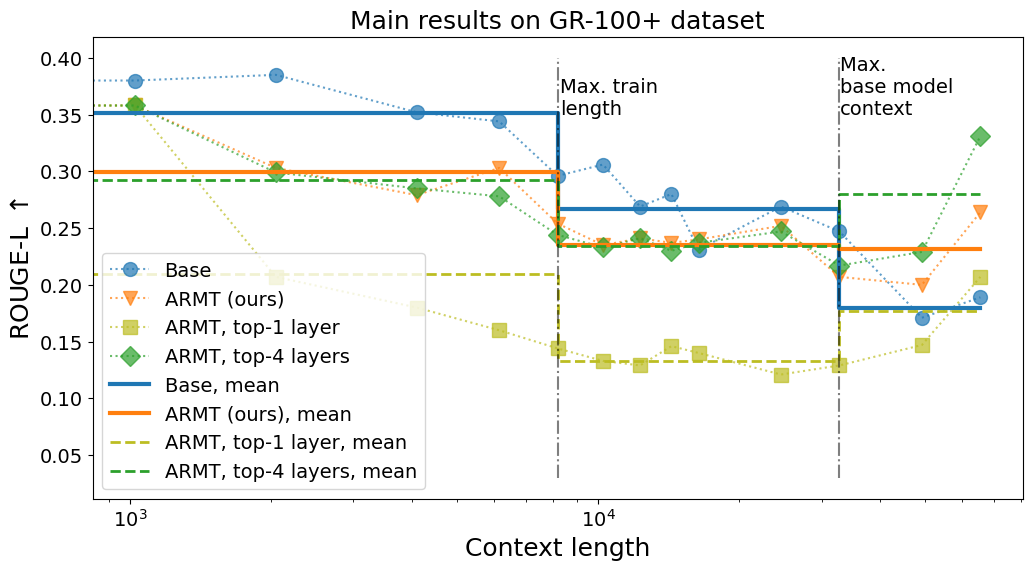

In [62]:

model_keys = [
    "Gemma-3-1B-IT, GR-100+, 8k",
    #"Mamba-train-64",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, 14th layer used",
    "ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-4 layers used",
    #"ARMT-Gemma-3-1B-IT, MT, 8k, top-4 layers trained",
    #"ARMT-Gemma-3-1B-IT, GR-100+, 8k, top-5 trained",
    #"ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain)",
]
model_names = [
    "Base",
    #"Mamba",
    "ARMT (ours)",
    "ARMT, top-1 layer",
    "ARMT, top-4 layers",
    #"ARMT, top-4 layers, trained",
    #"ARMT, pre-selected layers, \ntrained (ours)",
    #"ARMT, pretrained (ours)",
]
fig = plt.figure(figsize=(12,6))
cmap=mpl.colormaps["tab10"].colors
color_idx = [0,1,8, 2, 3]
x = np.array([0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]) * 1024
main_ids = [0, 1]

markers = ["o", "v", "s", "D", "*"]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    ms = 10 if markers[idx] != "*" else 12
    plt.plot(x, list(buf_res[key])[:1] + list(buf_res[key])[:len(x)-1], marker = markers[idx], ms=ms, alpha=0.7, linestyle=":",
             label=name, color=cmap[color_idx[idx]])
global_fs = 18
cmap=mpl.colormaps["tab10"].colors
new_x = np.array([0, 8, 8, 32, 32, 64]) * 1024
new_y_ids = [[0, 5], [0, 5], [5, 11], [5, 11], [11,13], [11,13]]
for idx, (key, name) in enumerate(zip(model_keys, model_names)):
    linewidth = 3 if idx in main_ids else 2
    linestyle = "-" if idx in main_ids else "--"
    new_y = [np.mean(np.array(list(buf_res[key]))[new_y_idx[0]:new_y_idx[-1]]) for new_y_idx in new_y_ids]
    #print(np.array(list(buf_res[key]))[new_y_ids[0][0]:new_y_ids[0][-1]])
    #print(key, new_y)
    plt.plot(new_x, new_y, label=name+", mean", alpha=1., color=cmap[color_idx[idx]], linestyle=linestyle, linewidth=linewidth)
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k"])[:len(x)-1], label="ARMT, 8k")
#plt.plot(x, list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:1] + list(buf_res["ARMT-Gemma-3-1B-IT, GR-100+, 8k (pretrain), prelim"])[:len(x)-1], label="ARMT, 8k, pretrained")

plt.vlines([32*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
plt.vlines([8*1024], ymin=0.03, ymax=0.4, linestyle="-.", color="k", alpha=0.5)
idx = 0
shift = [-100, -100, ]
train_sizes = [8*1024, 32*1024]
dnames = ["Max. train \nlength", "Max. \nbase model \ncontext"]
idx = 0
for x, y, text in zip(train_sizes, [0.36] * len(train_sizes), dnames):
    plt.text(x-shift[idx], y-0.01, text, fontsize=14)
    idx += 1
plt.xscale('log') 
plt.xlabel("Context length", fontsize=global_fs)
plt.ylabel("ROUGE-L $\\uparrow$", fontsize=global_fs)
plt.title("Main results on GR-100+ dataset", fontsize=global_fs)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.show()
fig.tight_layout()
fig.savefig("../../paper_results/poster_iclr_main_res_gr100_plus_gemma_small.pdf")

## Subset for Loss eval for pt model

In [50]:
# load and save subset of fineweb-edu for loss evals
from datasets import load_dataset
dataset = load_dataset('HuggingFaceFW/fineweb-edu', split='train', streaming=True)
data_subset = []
for idx in tqdm(range(1000)):
    data_subset.append(next(iter(dataset)))
    #print(next(iter(dataset)))

100%|██████████| 1000/1000 [15:09<00:00,  1.10it/s]


In [52]:
import datasets

In [53]:
fineweb_subset = datasets.Dataset.from_list(data_subset)

In [54]:
eval_data = datasets.DatasetDict(
    {"train": fineweb_subset,
     "validation": fineweb_subset,
     "test": fineweb_subset}
)

In [55]:
eval_data.save_to_disk("../../data/fineweb_train_subset")

Saving the dataset (1/1 shards): 100%|██████████| 1000/1000 [00:00<00:00, 87226.87 examples/s]


In [56]:
dataset = load_dataset('karpathy/fineweb-edu-100b-shuffle', split='train', streaming=True)
data_subset = []
for idx in tqdm(range(1000)):
    data_subset.append(next(iter(dataset)))
    #print(next(iter(dataset)))

100%|██████████| 1000/1000 [10:45<00:00,  1.55it/s]


In [57]:
fineweb_subset = datasets.Dataset.from_list(data_subset)
eval_data = datasets.DatasetDict(
    {"train": fineweb_subset,
     "validation": fineweb_subset,
     "test": fineweb_subset}
)

In [58]:
eval_data.save_to_disk("../../data/fineweb_train_subset_karp")

Saving the dataset (1/1 shards): 100%|██████████| 1000/1000 [00:00<00:00, 52851.61 examples/s]


## Subset PG19 for yarn

In [1]:
import datasets

/home/jovyan/gkuzmin/llm_ue/conda_llm_ue_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
from transformers import AutoTokenizer

In [9]:
from tqdm import tqdm

In [3]:
pg_dat = datasets.load_dataset("fla-hub/pg19")

Generating test split: 100%|██████████| 100/100 [00:00<00:00, 333.99 examples/s]


In [5]:
smol_tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-360M-Instruct")

In [8]:
smol_tok.eos_token

'<|im_end|>'

In [ ]:
split_res = {}
for split in pg_dat.keys():
    split_res[split] = []
    max_len = 32*1024
    max_samples = 5000
    bos, eos = smol_tok.bos_token, smol_tok.eos_token
    curr_len = 0
    curr_text = ""
    for el in tqdm(pg_dat[split]):
        buf_sample = smol_tok(el["text"], add_special_tokens=False)
        curr_len += len(buf_sample["input_ids"])
        curr_text += bos + el["text"] + eos
        if curr_len >= max_len:
            split_res[split].append(curr_text)
            curr_text = ""
            curr_len = 0
        if len(split_res[split]) > max_samples:
            break
        

100%|██████████| 100/100 [00:22<00:00,  4.52it/s]


In [12]:
len(split_res["train"])

5001

In [14]:
buf_df = datasets.DatasetDict(
    {key: datasets.Dataset.from_dict({"text": split_res[key]}) for key in split_res.keys()}
)

In [16]:
buf_df.save_to_disk("../../data/pg19_subset_yarn")

Saving the dataset (1/1 shards): 100%|██████████| 79/79 [00:00<00:00, 1996.08 examples/s]


In [17]:
split_res = {}
for split in pg_dat.keys():
    split_res[split] = []
    max_len = 32*1024
    max_samples = 30000
    bos, eos = smol_tok.bos_token, smol_tok.eos_token
    curr_len = 0
    curr_text = ""
    for el in tqdm(pg_dat[split]):
        buf_sample = smol_tok(el["text"], add_special_tokens=False)
        curr_len += len(buf_sample["input_ids"])
        curr_text += bos + el["text"] + eos
        if curr_len >= max_len:
            split_res[split].append(curr_text)
            curr_text = ""
            curr_len = 0
        if len(split_res[split]) > max_samples:
            break
        

100%|██████████| 100/100 [00:25<00:00,  3.86it/s]


In [18]:
len(split_res["train"])

23057

In [19]:
buf_df = datasets.DatasetDict(
    {key: datasets.Dataset.from_dict({"text": split_res[key]}) for key in split_res.keys()}
)

In [20]:
buf_df.save_to_disk("../../data/pg19_subset_yarn_full")

Saving the dataset (1/1 shards): 100%|██████████| 79/79 [00:00<00:00, 2034.38 examples/s]


# Calculate data stats

In [ ]:
import datasets
data_pathes = [
    "../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/",
    "../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/",
    "../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/",
    "../../data/gov_report/gov_report_0k_2k/",
    "../../data/gov_report/gov_report_0k_4k/",
    "../../data/gov_report/gov_report_0k_8k/",
    "../../data/gov_report_100_gen_plus/gov_report_0k_2k/",
    "../../data/gov_report_100_gen_plus/gov_report_0k_4k/",
    "../../data/gov_report_100_gen_plus/gov_report_0k_8k/",
]

In [491]:
for dpath in data_pathes:
    ds = datasets.load_from_disk(dpath)
    print(dpath)
    print(f"{np.round(len(ds['train']) / 1000, 1)}k & ", f"{np.round(len(ds['validation']) / 1000, 1)}k & ", f"{np.round(len(ds['test']) / 1000, 1)}k & ", np.mean(ds["train"]["length"]))

../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/
229.4k &  3.1k &  23.6k &  1172.5093511508605
../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k/
289.2k &  4.5k &  32.0k &  2191.8969485313187
../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/
328.3k &  5.1k &  34.7k &  3940.205497521759
../../data/gov_report/gov_report_0k_2k/
9.9k &  0.5k &  1.3k &  1557.8849843481773
../../data/gov_report/gov_report_0k_4k/
17.4k &  0.9k &  2.2k &  2839.9674498567333
../../data/gov_report/gov_report_0k_8k/
19.7k &  1.0k &  2.5k &  4781.661873793314
../../data/gov_report_100_gen_plus/gov_report_0k_2k/
90.5k &  0.5k &  1.3k &  1427.9492351562844
../../data/gov_report_100_gen_plus/gov_report_0k_4k/
121.7k &  0.9k &  2.2k &  2581.5798997452544
../../data/gov_report_100_gen_plus/gov_report_0k_8k/
128.4k &  1.0k &  2.5k &  4438.172931979569


# Extract examples

In [169]:
import datasets

In [170]:
ds = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k/")

In [198]:
short_ids = np.argsort(ds["train"]["length"])#[:1000]

In [211]:
idx = 5523
for key in ds["train"][0].keys():
    print(key)
    if key == "context":
        print(ds["train"][int(short_ids[idx])][key].replace("\n", "\\newline ").replace("_", "\_"))
    else:
        print(ds["train"][int(short_ids[idx])][key])

repo_name
viaict/viaduct
fname
['repos/viaict/viaduct/migrations/versions/2018_09_05_6aff43ad8f2a_change_company_description_to_text.py']
context
from typing import Any \newline import typing \newline [docstring] \newline from alembic import op \newline import sqlalchemy as sa \newline \newline \newline from sqlalchemy . ext . declarative import declarative\_base \newline from sqlalchemy . orm import sessionmaker , relationship \newline \newline [comment] \newline revision = [string] \newline down\_revision = [string] \newline \newline Base = declarative\_base ( ) \newline db = sa \newline db . Model = Base \newline db . relationship = relationship \newline \newline \newline def create\_session ( ) : \newline connection = op . get\_bind ( ) \newline session\_maker = sa . orm . sessionmaker ( ) \newline session = session\_maker ( bind = connection ) \newline db . session = session \newline \newline \newline def upgrade ( ) : \newline create\_session ( ) \newline \newline [comment] \newl

In [212]:
ds = datasets.load_from_disk("../../data/gov_report/gov_report_0k_2k/")

In [213]:
short_ids = np.argsort(ds["train"]["length"])#[:1000]

In [225]:
idx = 12 #2
for key in ds["train"][0].keys():
    print(key)
    if key == "context":
        #print(ds["train"][int(short_ids[idx])][key])
        print(ds["train"][int(short_ids[idx])][key].replace("\n", "\\newline ").replace("_", "\_"))
    else:
        print(ds["train"][int(short_ids[idx])][key])

doc_id
GAO_GAO-13-762T
context
Economic Significance of Intellectual Property Protection and Theft\newline As we reported in April 2010, IP is an important component of the U.S. economy and IP-related industries pay higher wages and contribute a significant percentage to the U.S. economy. However, the U.S. economy as a whole may grow at a slower pace than it otherwise would because of counterfeiting and piracy’s effect on U.S. industries, government, and consumers.\newline Quantifying Economic Impacts Is Difficult, However Industry Research Suggests the Impacts Are Sizable\newline Generally, as we reported in April 2010, the illicit nature of counterfeiting and piracy makes estimating the economic impact of IP infringements extremely difficult, so assumptions must be used to offset the lack of data. Efforts to estimate losses involve assumptions such as the rate at which consumers would substitute counterfeit for legitimate products, which can have enormous impacts on the resulting est

In [242]:
import datasets

In [243]:
mt_v2_bal_sup = datasets.load_from_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_64k_v2_bal_support")

In [245]:
mt_v2_bal_sup.push_to_hub("AIRI-NLP/test_mt_v2_0k_64k_balnced_support", private=True, token="")

Creating parquet from Arrow format: 100%|██████████| 2/2 [00:00<00:00, 14.64ba/s]
Uploading files as bytes or binary IO objects is not supported by Xet Storage. Falling back to HTTP upload.
Uploading the dataset shards: 100%|██████████| 1/1 [00:02<00:00,  2.09s/it]


CommitInfo(commit_url='https://huggingface.co/datasets/AIRI-NLP/test_mt_v2_0k_64k_balnced_support/commit/acf6e155ac8bf852f2c5736b311383877736ca40', commit_message='Upload dataset', commit_description='', oid='acf6e155ac8bf852f2c5736b311383877736ca40', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/AIRI-NLP/test_mt_v2_0k_64k_balnced_support', endpoint='https://huggingface.co', repo_type='dataset', repo_id='AIRI-NLP/test_mt_v2_0k_64k_balnced_support'), pr_revision=None, pr_num=None)

In [246]:
gov_rep_bal_sup = datasets.load_from_disk("../../data/gov_report/gov_report_0k_64k_test_only_bal_support")

In [247]:
gov_rep_bal_sup.push_to_hub("AIRI-NLP/test_gov_rep_0k_64k_balanced_support", private=True, token="")

Creating parquet from Arrow format: 100%|██████████| 2/2 [00:00<00:00, 17.47ba/s]
Uploading files as bytes or binary IO objects is not supported by Xet Storage. Falling back to HTTP upload.
Uploading the dataset shards: 100%|██████████| 1/1 [00:02<00:00,  2.15s/it]


CommitInfo(commit_url='https://huggingface.co/datasets/AIRI-NLP/test_gov_rep_0k_64k_balanced_support/commit/4ff47f75d391ff745529c5a0384cf9dc24e0cbd1', commit_message='Upload dataset', commit_description='', oid='4ff47f75d391ff745529c5a0384cf9dc24e0cbd1', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/AIRI-NLP/test_gov_rep_0k_64k_balanced_support', endpoint='https://huggingface.co', repo_type='dataset', repo_id='AIRI-NLP/test_gov_rep_0k_64k_balanced_support'), pr_revision=None, pr_num=None)